
# 1. BUSINESS PROBLEM UNDERSTANDING

## 1.1 Business Background

Agriculture plays a significant role in the economy and food security of many countries. Rice is one of the most important staple crops, and its production is affected by several plant diseases.

Rice plants are vulnerable to various leaf diseases, which can negatively impact crop health, productivity and overall agricultural output.

Three major diseases considered in this project are:

- Leaf Smut
- Brown Spot
- Bacterial Leaf Blight

Identifying these diseases at an early stage is important for supporting timely agricultural intervention and reducing potential crop losses.

Traditionally, disease identification relies on visual inspection by farmers or agricultural experts. However, manual identification can be time-consuming and may require specialized knowledge.

With the advancement of Artificial Intelligence and Computer Vision, image classification techniques can be used to automate the identification of plant diseases from leaf images.

## 1.2 Business Problem

The objective of this project is to develop an automated Rice Leaf Disease Detection system using Deep Learning techniques.

The system should analyze an uploaded image of a rice leaf and classify it into one of the three disease categories:

1. Leaf Smut
2. Brown Spot
3. Bacterial Leaf Blight

The project aims to reduce the dependency on manual visual inspection and demonstrate how Deep Learning can support faster and more consistent identification of rice leaf diseases.

## 1.3 Business Objective

The key business objectives are:

- Develop an automated image classification system for rice leaf disease detection.
- Identify the three disease categories accurately using leaf images.
- Apply Convolutional Neural Networks (CNN) for image classification.
- Experiment with data augmentation techniques to improve model generalization.
- Compare multiple Deep Learning architectures.
- Evaluate model performance using appropriate classification metrics.
- Identify the most suitable model for potential production deployment.

## 1.4 Expected Business Outcome

The expected outcome is a Deep Learning-based classification model that can:

- Accept a rice leaf image as input.
- Predict the corresponding disease category.
- Provide prediction probabilities for each disease class.
- Support faster preliminary disease identification.
- Demonstrate the potential application of AI in smart agriculture.

The developed system is intended as a prototype decision-support tool and not as a replacement for professional agricultural diagnosis.


# 2. PROJECT OBJECTIVE

## 2.1 Primary Objective

To develop a Deep Learning-based image classification model capable of identifying three major rice leaf diseases: Leaf Smut, Brown Spot and Bacterial Leaf Blight.

## 2.2 Specific Objectives

1. Perform Exploratory Data Analysis (EDA) to understand the dataset.
2. Examine image quality, dimensions and class distribution.
3. Perform image preprocessing and normalization.
4. Apply data augmentation techniques to improve model generalization.
5. Develop a Convolutional Neural Network (CNN) model.
6. Experiment with transfer learning architectures.
7. Compare model performance using appropriate evaluation metrics.
8. Identify the best-performing model based on validation and test results.
9. Analyze model limitations and challenges.
10. Recommend a suitable model for potential production deployment.

## 2.3 Scope of the Project

The project focuses on image-based classification of rice leaf diseases using the three classes provided in the dataset.

The model will accept a rice leaf image and predict its corresponding disease category.

## 2.4 Expected Deliverables

- Exploratory Data Analysis report.
- Preprocessed image dataset.
- CNN classification model.
- Data augmentation experiments.
- Model comparison report.
- Classification performance metrics.
- Confusion matrix.
- Challenges and solutions documentation.
- Final trained model.


# 3. DATASET DESCRIPTION

## 3.1 Dataset Overview

The Rice Leaf Disease Detection dataset is provided as part of the PRCP-1001 Capstone Project.

The dataset consists of 120 JPG images of disease-infected rice leaves. The images are categorized into three different disease classes, with 40 images belonging to each class.

## 3.2 Dataset Characteristics

| Attribute | Description |
|---|---|
| Project ID | PRCP-1001 |
| Dataset Name | Rice Leaf Disease Detection |
| Data Type | Image Data |
| Image Format | JPG |
| Total Images | 120 |
| Number of Classes | 3 |
| Images per Class | 40 |
| Learning Type | Supervised Learning |
| Problem Type | Multi-class Image Classification |
| Domain | Agriculture |

## 3.3 Target Classes

The dataset contains the following three disease categories:

1. **Leaf Smut:** Rice leaves affected by leaf smut disease.
2. **Brown Spot:** Rice leaves affected by brown spot disease.
3. **Bacterial Leaf Blight:** Rice leaves affected by bacterial leaf blight.

## 3.4 Dataset Distribution

The dataset specification indicates an equal distribution of images across all three classes.

| Disease Class | Number of Images |
|---|---:|
| Leaf Smut | 40 |
| Brown Spot | 40 |
| Bacterial Leaf Blight | 40 |
| **Total** | **120** |

## 3.5 Input and Output Description

**Input:** A JPG image of a rice leaf.

**Output:** One of the three disease categories predicted by the trained classification model.

## 3.6 Dataset Source

The dataset is provided through the DataMites Capstone Project resource.

Dataset Link:
https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip

## 3.7 Dataset Considerations

- The dataset contains a relatively small number of images.
- Image quality and dimensions need to be investigated.
- Class distribution needs to be verified after downloading.
- Data augmentation will be explored to improve model generalization.
- The possibility of duplicate images and data leakage will be investigated.


In [4]:

# ==========================================
# 4. IMPORTING REQUIRED LIBRARIES
# ==========================================

# Basic Python libraries
import os
import sys
import random
import warnings
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Machine Learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Downloading utilities
import requests
from tqdm.auto import tqdm

# Ignore unnecessary warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

# Setting random seeds

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed configured:", SEED)


Random seed configured: 42


In [6]:

# Checking environment versions

print("Python Version:", sys.version)
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("Matplotlib Version:", plt.matplotlib.__version__)


Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
TensorFlow Version: 2.21.0
NumPy Version: 2.3.5
Pandas Version: 2.3.3
Matplotlib Version: 3.10.6


In [8]:

# Visualization configuration

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

sns.set_style("whitegrid")

print("Visualization settings configured!")


Visualization settings configured!


In [9]:

from pathlib import Path

# Current notebook directory
PROJECT_DIR = Path.cwd()

# Create required folders
DATASET_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [DATASET_DIR, MODEL_DIR, OUTPUT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("All project folders created successfully!")


Project directory: C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease
All project folders created successfully!


In [10]:

import requests
from tqdm.auto import tqdm

DATASET_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"

ZIP_PATH = DATASET_DIR / "RiceLeaf.zip"

if not ZIP_PATH.exists():

    response = requests.get(
        DATASET_URL,
        stream=True,
        timeout=120
    )

    response.raise_for_status()

    total_size = int(response.headers.get("content-length", 0))

    with open(ZIP_PATH, "wb") as file:

        with tqdm(
            total=total_size,
            unit="B",
            unit_scale=True,
            desc="Downloading Dataset"
        ) as progress:

            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    file.write(chunk)
                    progress.update(len(chunk))

    print("Dataset downloaded successfully!")

else:
    print("Dataset already downloaded!")

print("ZIP location:", ZIP_PATH)


Dataset downloaded successfully!
ZIP location: C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\dataset\RiceLeaf.zip



# 6. EXPLORATORY DATA ANALYSIS (EDA)

## 6.1 Dataset Structure Analysis

Exploratory Data Analysis is performed to understand the structure, characteristics and quality of the dataset before model development.

In this project, EDA focuses on examining the rice leaf images, identifying disease categories, checking image dimensions, analyzing class distribution and detecting potential data quality issues.

The analysis helps determine appropriate preprocessing techniques and supports informed decisions during model development.


In [15]:

# ============================================
# EXTRACT RICE LEAF DATASET
# ============================================

import zipfile

ZIP_PATH = DATASET_DIR / "RiceLeaf.zip"

EXTRACT_DIR = DATASET_DIR / "RiceLeaf_Extracted"

# Create extraction directory
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Extract ZIP file
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Extraction Location:", EXTRACT_DIR)


Dataset extracted successfully!
Extraction Location: C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\dataset\RiceLeaf_Extracted


In [16]:

# ============================================
# VERIFY TOTAL DATASET IMAGES
# ============================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

image_files = [
    file for file in EXTRACT_DIR.rglob("*")
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
]

print("Total extracted images:", len(image_files))


Total extracted images: 0


In [18]:

# ============================================
# IDENTIFY DATASET CLASSES
# ============================================

for folder in EXTRACT_DIR.rglob("*"):

    if folder.is_dir():

        images = [
            file for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        ]

        if images:
            print(folder.name, ":", len(images), "images")


In [19]:

# ============================================
# INSPECT ORIGINAL ZIP FILE
# ============================================

import zipfile

ZIP_PATH = DATASET_DIR / "RiceLeaf.zip"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

    all_files = zip_ref.namelist()

    print("TOTAL FILES IN ZIP:", len(all_files))

    print("\nFIRST 30 FILES:")

    for file in all_files[:30]:
        print(file)


TOTAL FILES IN ZIP: 3

FIRST 30 FILES:
Data/Leaf smut-20200814T055530Z-001.zip
Data/Brown spot-20200814T055208Z-001.zip
Data/Bacterial leaf blight-20200814T055237Z-001.zip


In [20]:

# ============================================
# EXTRACT NESTED DISEASE DATASETS
# ============================================

import zipfile
from pathlib import Path

# Locate Data folder
DATA_FOLDER = EXTRACT_DIR / "Data"

# Create a folder for each disease
DISEASE_DIR = DATASET_DIR / "RiceLeaf_Images"

DISEASE_DIR.mkdir(parents=True, exist_ok=True)

# Extract individual disease ZIP files
for zip_file in DATA_FOLDER.glob("*.zip"):

    # Extract ZIP filename as disease name
    disease_name = zip_file.name.split("-2020")[0]

    disease_folder = DISEASE_DIR / disease_name

    disease_folder.mkdir(parents=True, exist_ok=True)

    print("Extracting:", disease_name)

    with zipfile.ZipFile(zip_file, "r") as zip_ref:

        for member in zip_ref.infolist():

            target = (disease_folder / member.filename).resolve()

            if not target.is_relative_to(disease_folder.resolve()):
                raise ValueError("Unsafe archive path detected")

        zip_ref.extractall(disease_folder)

    print("Successfully extracted:", disease_name)

print("\nAll three disease datasets extracted!")


Extracting: Bacterial leaf blight
Successfully extracted: Bacterial leaf blight
Extracting: Brown spot
Successfully extracted: Brown spot
Extracting: Leaf smut
Successfully extracted: Leaf smut

All three disease datasets extracted!


In [21]:

# ============================================
# VERIFY DISEASE FOLDERS
# ============================================

for root, dirs, files in os.walk(DISEASE_DIR):

    level = root.replace(str(DISEASE_DIR), "").count(os.sep)

    print("    " * level + os.path.basename(root) + "/")

    for file in files[:3]:
        print("    " * (level + 1) + file)


RiceLeaf_Images/
    Bacterial leaf blight/
        Bacterial leaf blight/
            DSC_0365.JPG
            DSC_0366.jpg
            DSC_0367.JPG
    Brown spot/
        Brown spot/
            DSC_0100.jpg
            DSC_0101.jpg
            DSC_0104.jpg
    Leaf smut/
        Leaf smut/
            DSC_0293.JPG
            DSC_0308.JPG
            DSC_0309.JPG


In [22]:

# ============================================
# COUNT IMAGES IN EACH DISEASE CLASS
# ============================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

class_counts = {}

for disease_folder in DISEASE_DIR.iterdir():

    if disease_folder.is_dir():

        images = [
            file for file in disease_folder.rglob("*")
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        ]

        class_counts[disease_folder.name] = len(images)

        print(
            disease_folder.name,
            ":",
            len(images),
            "images"
        )

print("-" * 40)

total_images = sum(class_counts.values())

print("TOTAL IMAGES:", total_images)


Bacterial leaf blight : 40 images
Brown spot : 40 images
Leaf smut : 39 images
----------------------------------------
TOTAL IMAGES: 119


In [23]:

# ============================================
# INVESTIGATE LEAF SMUT IMAGE COUNT
# ============================================

leaf_smut_zip = list(DATA_FOLDER.glob("Leaf smut*.zip"))[0]

with zipfile.ZipFile(leaf_smut_zip, "r") as zip_ref:

    zip_contents = zip_ref.namelist()

    print("Total files inside Leaf Smut ZIP:",
          len(zip_contents))

    print("\nFiles inside Leaf Smut ZIP:")

    for file in zip_contents:
        print(file)


Total files inside Leaf Smut ZIP: 39

Files inside Leaf Smut ZIP:
Leaf smut/DSC_0313.JPG
Leaf smut/DSC_0510.jpg
Leaf smut/DSC_0503.jpg
Leaf smut/DSC_0318.JPG
Leaf smut/DSC_0501.jpg
Leaf smut/DSC_0312.JPG
Leaf smut/DSC_0339.jpg
Leaf smut/DSC_0504.jpg
Leaf smut/DSC_0500.jpg
Leaf smut/DSC_0514.jpg
Leaf smut/DSC_0314.JPG
Leaf smut/DSC_0511.jpg
Leaf smut/DSC_0319.jpg
Leaf smut/DSC_0516.jpg
Leaf smut/DSC_0515.jpg
Leaf smut/DSC_0512.jpg
Leaf smut/DSC_0507.jpg
Leaf smut/DSC_0315.jpg
Leaf smut/DSC_0320.JPG
Leaf smut/DSC_0502.jpg
Leaf smut/DSC_0513.jpg
Leaf smut/DSC_0509.jpg
Leaf smut/DSC_0505.jpg
Leaf smut/DSC_0506.jpg
Leaf smut/DSC_0321.JPG
Leaf smut/DSC_0338.JPG
Leaf smut/DSC_0309.JPG
Leaf smut/DSC_0322.jpg
Leaf smut/DSC_0327.JPG
Leaf smut/DSC_0317.JPG
Leaf smut/DSC_0336.jpg
Leaf smut/DSC_0308.JPG
Leaf smut/DSC_0331.JPG
Leaf smut/DSC_0310.JPG
Leaf smut/DSC_0335.JPG
Leaf smut/DSC_0328.jpg
Leaf smut/DSC_0330.jpg
Leaf smut/DSC_0293.JPG
Leaf smut/DSC_0316.JPG


In [24]:

# ============================================
# CHECK IMAGE FILE EXTENSIONS
# ============================================

from collections import Counter

leaf_smut_folder = DISEASE_DIR / "Leaf smut"

extension_counts = Counter(
    file.suffix.lower()
    for file in leaf_smut_folder.rglob("*")
    if file.is_file()
)

print("Leaf Smut file extensions:")
print(extension_counts)


Leaf Smut file extensions:
Counter({'.jpg': 39})


In [25]:

# ============================================
# IMAGE INTEGRITY CHECK
# ============================================

corrupted_images = []

for image_path in DISEASE_DIR.rglob("*"):

    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:

        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception as error:
            corrupted_images.append(str(image_path))

print("Corrupted images:", len(corrupted_images))

for image in corrupted_images:
    print(image)


Corrupted images: 0



### 6.2.1 Initial Dataset Distribution Findings

The initial dataset inspection identified 119 images across three disease categories.

The expected dataset size, according to the project specification, is 120 images, with 40 images per class.

However, the extracted dataset contains:

- Bacterial Leaf Blight: 40 images
- Brown Spot: 40 images
- Leaf Smut: 39 images

This indicates a discrepancy of one image in the Leaf Smut category.

Further investigation is required to determine whether the missing image is due to the original archive contents, file extraction or image integrity issues.

The dataset will not be artificially balanced by duplicating images. Appropriate data handling techniques will be considered after completing the data quality assessment.



### 6.2.2 Data Quality Investigation – Missing Image

During the initial dataset validation, 119 images were identified instead of the expected 120 images.

Further investigation was performed on the original Leaf Smut ZIP archive.

The following observations were recorded:

- The original Leaf Smut archive contains only 39 image files.
- All 39 files have the JPG extension.
- No corrupted images were detected during image integrity validation.
- The extraction process was successful.

**Conclusion:**

The discrepancy originates from the supplied dataset archive rather than the extraction process. The project specification indicates 40 Leaf Smut images, while the actual source archive contains 39.

The original data will be preserved without artificially duplicating images. This discrepancy will be considered during model development and evaluation.



## 6.3 Image Dimensions and Quality Analysis

Image quality analysis is performed to understand the technical characteristics of the rice leaf images before preprocessing.

The analysis includes:

1. Image width and height.
2. Image resolution.
3. Image colour mode (RGB, RGBA or Grayscale).
4. Image format.
5. File size.
6. Identification of inconsistent image dimensions.

This analysis helps determine the appropriate image resizing and preprocessing techniques required for CNN model development.


In [26]:

# ============================================
# IMAGE DIMENSIONS AND QUALITY ANALYSIS
# ============================================

image_metadata = []

for image_path in DISEASE_DIR.rglob("*"):

    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:

        try:
            with Image.open(image_path) as img:

                width, height = img.size

                image_metadata.append({
                    "Image_Name": image_path.name,
                    "Disease_Class": image_path.parent.name,
                    "Width": width,
                    "Height": height,
                    "Resolution": width * height,
                    "Color_Mode": img.mode,
                    "Format": img.format,
                    "File_Size_KB": round(
                        image_path.stat().st_size / 1024, 2
                    ),
                    "Image_Path": str(image_path)
                })

        except Exception as error:
            print("Error reading:", image_path, error)

# Create DataFrame
image_metadata_df = pd.DataFrame(image_metadata)

print("Total images analyzed:", len(image_metadata_df))

display(image_metadata_df.head(10))


Total images analyzed: 119


,Image_Name,Disease_Class,Width,Height,Resolution,Color_Mode,Format,File_Size_KB,Image_Path
0,DSC_0293.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,345.64,C:\Users\brind_0lf2fog\Capstone Project Datami...
1,DSC_0308.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,398.88,C:\Users\brind_0lf2fog\Capstone Project Datami...
2,DSC_0309.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,423.38,C:\Users\brind_0lf2fog\Capstone Project Datami...
3,DSC_0310.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,413.13,C:\Users\brind_0lf2fog\Capstone Project Datami...
4,DSC_0312.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,363.34,C:\Users\brind_0lf2fog\Capstone Project Datami...
5,DSC_0313.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,365.53,C:\Users\brind_0lf2fog\Capstone Project Datami...
6,DSC_0314.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,391.19,C:\Users\brind_0lf2fog\Capstone Project Datami...
7,DSC_0315.jpg,Leaf smut,3081,897,2763657,RGB,JPEG,362.92,C:\Users\brind_0lf2fog\Capstone Project Datami...
8,DSC_0316.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,357.75,C:\Users\brind_0lf2fog\Capstone Project Datami...
9,DSC_0317.JPG,Leaf smut,3081,897,2763657,RGB,JPEG,369.78,C:\Users\brind_0lf2fog\Capstone Project Datami...


In [27]:

# Statistical summary

print("IMAGE DIMENSION STATISTICS")

display(
    image_metadata_df[
        ["Width", "Height", "Resolution", "File_Size_KB"]
    ].describe().round(2)
)


IMAGE DIMENSION STATISTICS


,Width,Height,Resolution,File_Size_KB
count,119.00,119.00,119.00,119.00
mean,2383.64,707.74,2025985.50,307.77
std,1123.53,311.66,1176542.77,172.70
min,250.00,71.00,21371.00,22.76
25%,1074.00,377.00,403836.00,102.66
50%,3081.00,897.00,2763657.00,379.45
75%,3081.00,897.00,2763657.00,426.88
max,3081.00,900.00,2763657.00,643.40


In [28]:

# Unique image dimensions

dimension_counts = (
    image_metadata_df
    .groupby(["Width", "Height"])
    .size()
    .reset_index(name="Image_Count")
    .sort_values("Image_Count", ascending=False)
)

print("Unique image dimensions:", len(dimension_counts))

display(dimension_counts.head(20))


Unique image dimensions: 34


,Width,Height,Image_Count
33,3081,897,85
0,250,200,2
2,296,88,1
3,301,71,1
32,1530,371,1
31,1504,323,1
30,1480,279,1
29,1200,900,1
28,948,233,1
27,948,211,1


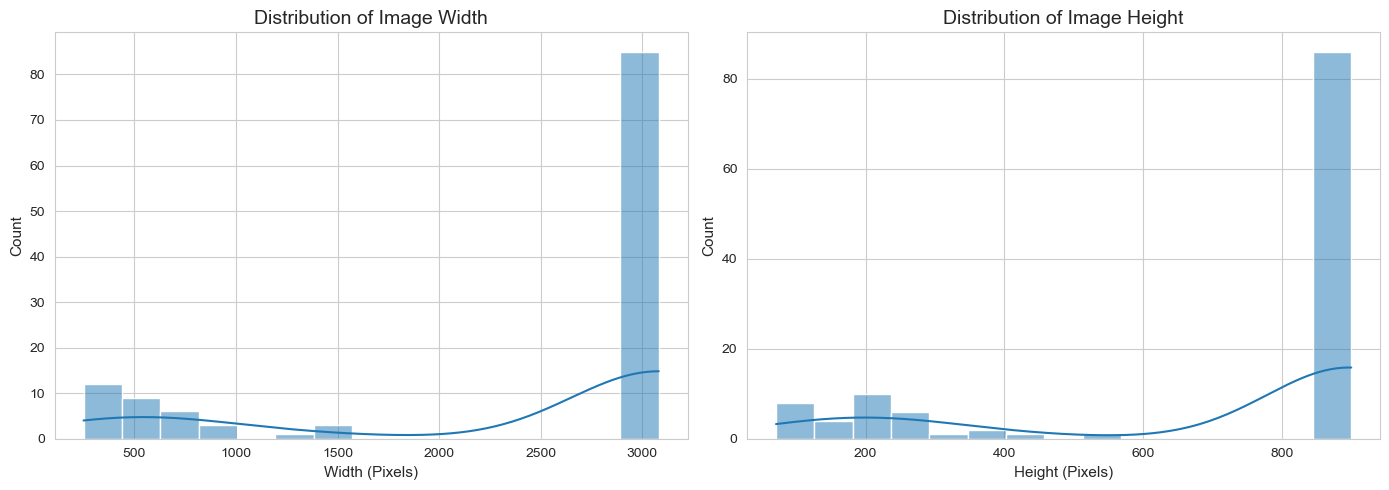

In [29]:

# Image width and height distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    image_metadata_df["Width"],
    bins=15,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Image Width")
axes[0].set_xlabel("Width (Pixels)")

sns.histplot(
    image_metadata_df["Height"],
    bins=15,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Image Height")
axes[1].set_xlabel("Height (Pixels)")

plt.tight_layout()
plt.show()


Image Color Mode Distribution:


Color_Mode
RGB    119
Name: count, dtype: int64

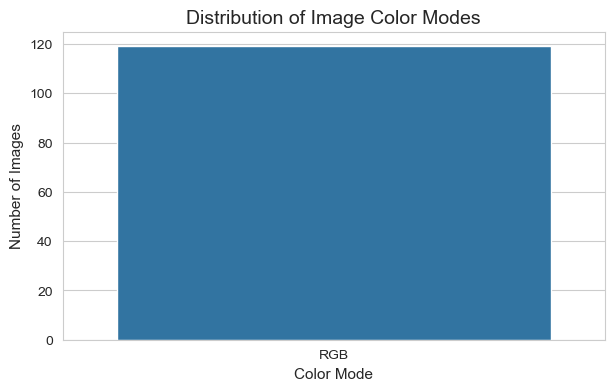

In [30]:

# Colour mode distribution

color_distribution = (
    image_metadata_df["Color_Mode"]
    .value_counts()
)

print("Image Color Mode Distribution:")

display(color_distribution)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=image_metadata_df,
    x="Color_Mode"
)

plt.title("Distribution of Image Color Modes")
plt.xlabel("Color Mode")
plt.ylabel("Number of Images")

plt.show()



### 6.3.1 Image Dimensions and Quality – Key Findings

The image metadata analysis was performed on 119 rice leaf images.

The following observations were identified:

1. All 119 images are in RGB colour mode, indicating consistent three-channel colour representation.

2. The dataset contains 34 unique image dimensions, indicating variation in image resolution.

3. The most common image dimension is 3081 × 897 pixels, observed in 85 images.

4. The average image width is 2383.64 pixels, while the average image height is 707.74 pixels.

5. The image width ranges from 250 to 3081 pixels, and image height ranges from 71 to 900 pixels.

6. The considerable variation in image dimensions indicates the need for image resizing and standardization before CNN training.

**Conclusion:**

The dataset has consistent RGB colour representation but varying image dimensions and resolutions. Image preprocessing will therefore be required to standardize the input shape. Aspect ratio preservation will be considered to minimize distortion of disease-related visual patterns.



## 6.4 Visual Inspection of Rice Leaf Images

Visual inspection is performed to understand the appearance of rice leaf images across the three disease categories.

Representative images from each disease class are displayed to examine:

- Visible disease symptoms.
- Leaf colour and texture.
- Background variations.
- Image quality and clarity.
- Differences in visual characteristics between disease classes.

This analysis helps understand the visual patterns that the Deep Learning model may learn during training.


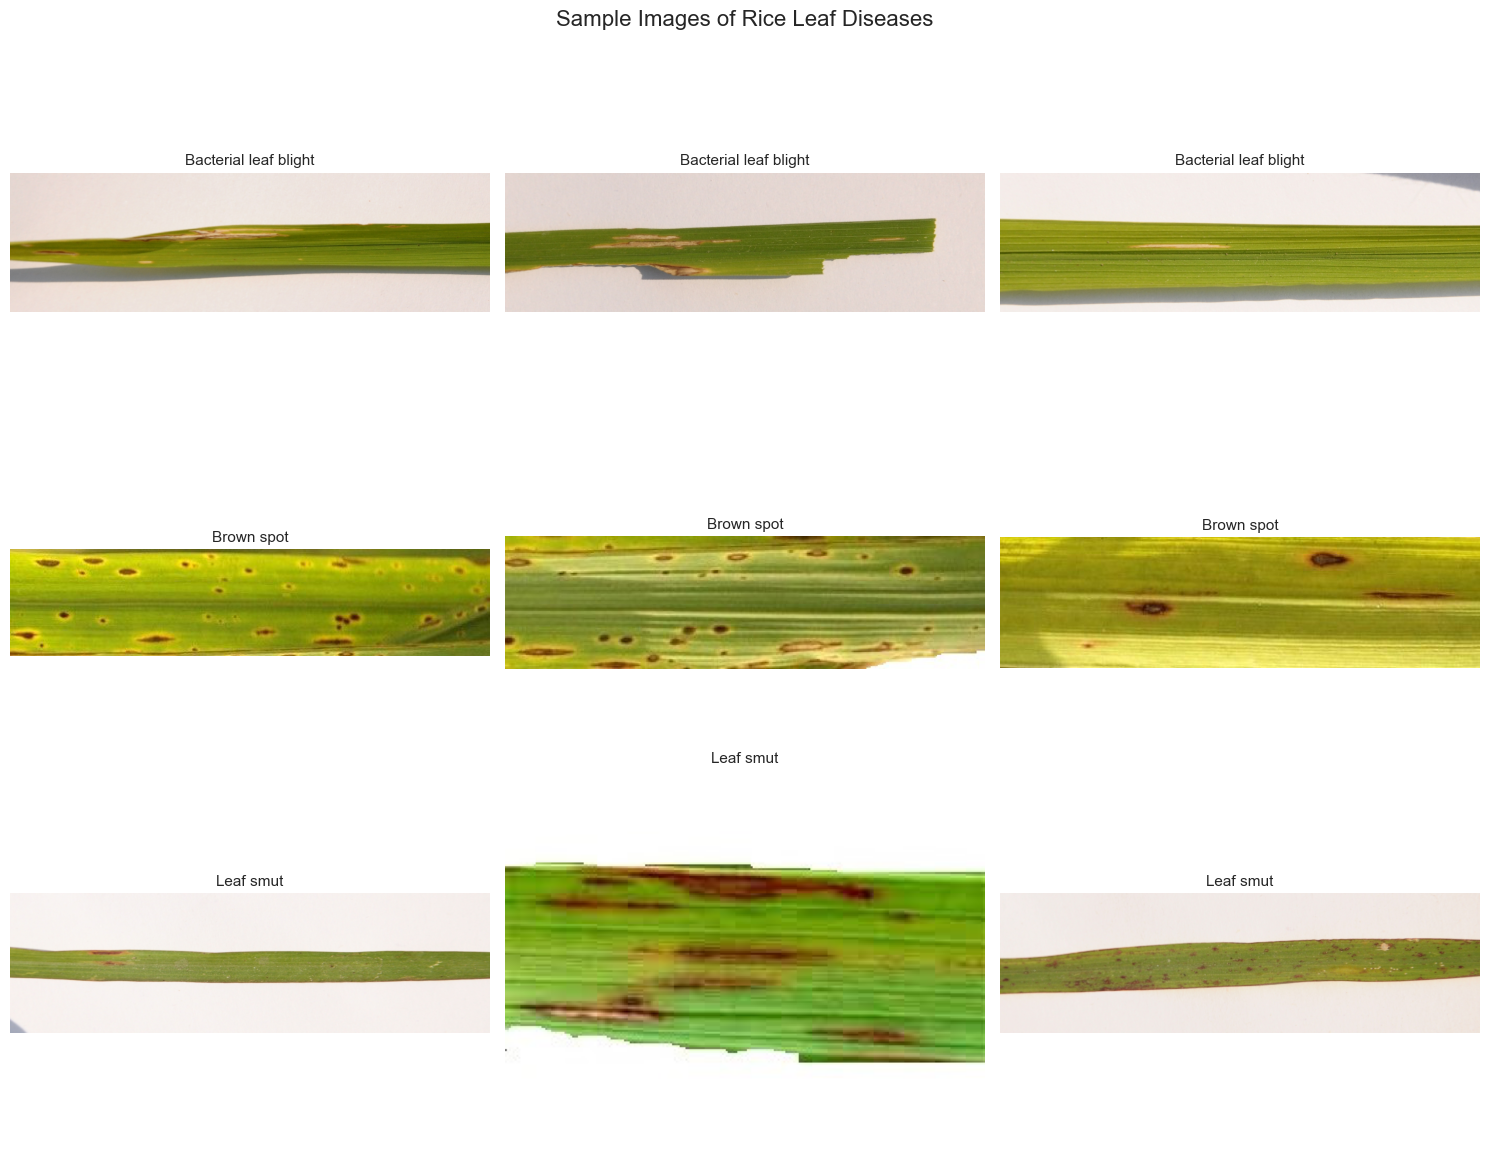

In [31]:

# ============================================
# VISUALIZE SAMPLE IMAGES FROM EACH CLASS
# ============================================

import matplotlib.pyplot as plt
import random
from PIL import Image

random.seed(42)

disease_classes = sorted([
    folder for folder in DISEASE_DIR.iterdir()
    if folder.is_dir()
])

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 12)
)

for row, disease_folder in enumerate(disease_classes):

    images = [
        file for file in disease_folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected_images = random.sample(
        images, min(3, len(images))
    )

    for col, image_path in enumerate(selected_images):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(
            disease_folder.name,
            fontsize=11
        )

        axes[row, col].axis("off")

plt.suptitle(
    "Sample Images of Rice Leaf Diseases",
    fontsize=16
)

plt.tight_layout()
plt.show()


,Image_Name,Disease_Class,Width,Height,Aspect_Ratio
0,DSC_0293.JPG,Leaf smut,3081,897,3.434783
1,DSC_0308.JPG,Leaf smut,3081,897,3.434783
2,DSC_0309.JPG,Leaf smut,3081,897,3.434783
3,DSC_0310.JPG,Leaf smut,3081,897,3.434783
4,DSC_0312.JPG,Leaf smut,3081,897,3.434783
5,DSC_0313.JPG,Leaf smut,3081,897,3.434783
6,DSC_0314.JPG,Leaf smut,3081,897,3.434783
7,DSC_0315.jpg,Leaf smut,3081,897,3.434783
8,DSC_0316.JPG,Leaf smut,3081,897,3.434783
9,DSC_0317.JPG,Leaf smut,3081,897,3.434783



Aspect Ratio Statistics:


count    119.00
mean       3.33
std        0.65
min        1.25
25%        3.43
50%        3.43
75%        3.43
max        5.30
Name: Aspect_Ratio, dtype: float64

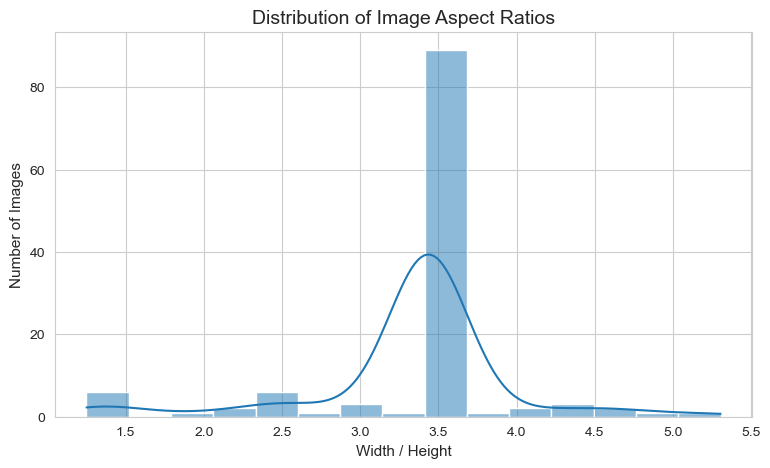

In [32]:

# ============================================
# ASPECT RATIO ANALYSIS
# ============================================

image_metadata_df["Aspect_Ratio"] = (
    image_metadata_df["Width"] /
    image_metadata_df["Height"]
)

display(
    image_metadata_df[
        ["Image_Name", "Disease_Class",
         "Width", "Height", "Aspect_Ratio"]
    ].head(10)
)

print("\nAspect Ratio Statistics:")

display(
    image_metadata_df["Aspect_Ratio"]
    .describe()
    .round(2)
)

plt.figure(figsize=(9, 5))

sns.histplot(
    image_metadata_df["Aspect_Ratio"],
    bins=15,
    kde=True
)

plt.title("Distribution of Image Aspect Ratios")
plt.xlabel("Width / Height")
plt.ylabel("Number of Images")

plt.show()



### 6.4.1 Visual Inspection – Key Findings

Visual inspection was performed using representative images from all three disease categories.

The following observations were identified:

**Bacterial Leaf Blight:**
- Images contain long, narrow green rice leaves.
- Some samples exhibit visible yellowish and brownish damaged regions.
- Backgrounds are relatively light in the displayed samples.

**Brown Spot:**
- Images exhibit distinct brown and dark oval-shaped lesions.
- Multiple spots can be observed across the leaf surface.
- Disease-related patterns are visually noticeable.

**Leaf Smut:**
- Images contain brown and dark streak-like markings.
- Variations in image clarity are visible across the displayed samples.
- Fine disease-related patterns need to be preserved during preprocessing.

**Overall Observations:**

- The images exhibit variations in background and visual quality.
- Disease symptoms are represented through colour, texture and lesion patterns.
- Some images have a wide aspect ratio.
- Direct square resizing may distort the original leaf structures.

**Conclusion:**

Visual inspection indicates that the dataset contains potentially useful disease-specific visual features. Appropriate image preprocessing is required to preserve leaf morphology and disease-related patterns before CNN training.



### 6.4.2 Aspect Ratio Analysis – Key Findings

Aspect ratio analysis was performed to understand the variation in image proportions.

The following statistical observations were identified:

- Mean aspect ratio: 3.33
- Median aspect ratio: 3.43
- Minimum aspect ratio: 1.25
- Maximum aspect ratio: 5.30
- Standard deviation: 0.65

The majority of images have an aspect ratio of approximately 3.43, indicating that the rice leaves are captured in a wide horizontal format.

**Conclusion:**

Direct resizing into a square input shape may distort important disease characteristics. Therefore, aspect-ratio-preserving resizing and suitable image cropping techniques will be evaluated during preprocessing.



## 6.5 Duplicate Image Detection

Duplicate image detection is performed to identify repeated images within the dataset.

Duplicate images may introduce data leakage if identical images are distributed across training and testing datasets.

A cryptographic hash-based technique is used to identify exact duplicate image files.

This analysis helps improve dataset quality and ensures more reliable model evaluation.


In [35]:

# ============================================
# EXACT DUPLICATE IMAGE DETECTION
# ============================================

import hashlib

def calculate_image_hash(image_path):

    hash_object = hashlib.md5()

    with open(image_path, "rb") as file:

        for chunk in iter(lambda: file.read(4096), b""):
            hash_object.update(chunk)

    return hash_object.hexdigest()


hash_records = []

for image_path in DISEASE_DIR.rglob("*"):

    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:

        image_hash = calculate_image_hash(image_path)

        hash_records.append({
            "Image_Name": image_path.name,
            "Disease_Class": image_path.parent.name,
            "Image_Path": str(image_path),
            "Image_Hash": image_hash
        })

hash_df = pd.DataFrame(hash_records)

# Identify repeated hashes
duplicate_images = hash_df[
    hash_df.duplicated(
        subset=["Image_Hash"],
        keep=False
    )
].sort_values("Image_Hash")

print("Total images checked:", len(hash_df))

print(
    "Number of duplicate image files:",
    hash_df.duplicated(
        subset=["Image_Hash"]
    ).sum()
)

display(duplicate_images)


Total images checked: 119
Number of duplicate image files: 0


,Image_Name,Disease_Class,Image_Path,Image_Hash



### 6.5.1 Duplicate Image Detection – Findings

Exact duplicate image detection was performed using the MD5 hashing technique.

The analysis covered all 119 images across the three disease categories.

The following observations were recorded:

- Total images analyzed: 119
- Exact duplicate images detected: 0
- Unique image files: 119

**Conclusion:**

No exact duplicate image files were identified in the dataset.

This reduces the risk of identical image files appearing in multiple dataset partitions. However, perceptually similar images may still exist and require separate investigation.

The dataset will be preserved without removing any images based on the current duplicate detection results.



## 6.6 Class-wise Data Quality Analysis

Class-wise data quality analysis is performed to understand whether image characteristics vary across the three disease categories.

The analysis compares:

- Average image width.
- Average image height.
- Average image resolution.
- Average image file size.
- Average aspect ratio.

This helps identify potential differences in image acquisition and quality across the disease classes.


In [36]:

# ============================================
# CLASS-WISE IMAGE QUALITY ANALYSIS
# ============================================

class_quality_summary = (
    image_metadata_df
    .groupby("Disease_Class")
    .agg(
        Total_Images=("Image_Name", "count"),
        Average_Width=("Width", "mean"),
        Average_Height=("Height", "mean"),
        Average_Resolution=("Resolution", "mean"),
        Average_File_Size_KB=("File_Size_KB", "mean"),
        Average_Aspect_Ratio=("Aspect_Ratio", "mean")
    )
    .round(2)
)

display(class_quality_summary)


,Total_Images,Average_Width,Average_Height,Average_Resolution,Average_File_Size_KB,Average_Aspect_Ratio
Disease_Class,,,,,,
Bacterial leaf blight,40,3081.00,897.00,2763657.00,432.87,3.43
Brown spot,40,1951.28,589.17,1556466.08,240.24,3.28
Leaf smut,39,2111.85,635.23,1750957.74,248.73,3.25


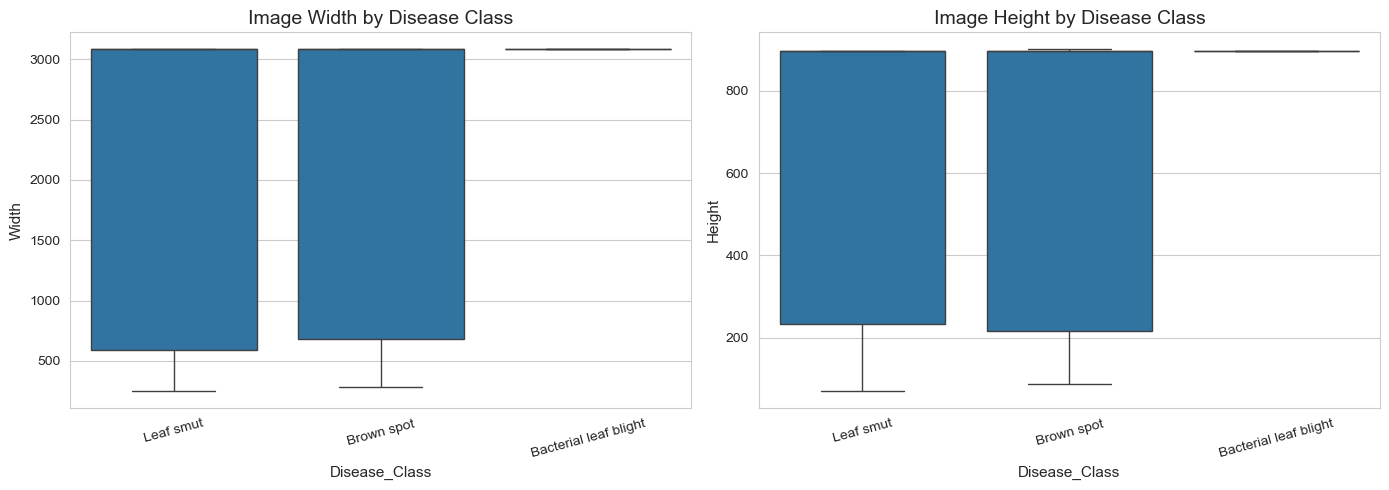

In [37]:

# ============================================
# CLASS-WISE DIMENSION COMPARISON
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=image_metadata_df,
    x="Disease_Class",
    y="Width",
    ax=axes[0]
)

axes[0].set_title("Image Width by Disease Class")
axes[0].tick_params(axis="x", rotation=15)

sns.boxplot(
    data=image_metadata_df,
    x="Disease_Class",
    y="Height",
    ax=axes[1]
)

axes[1].set_title("Image Height by Disease Class")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


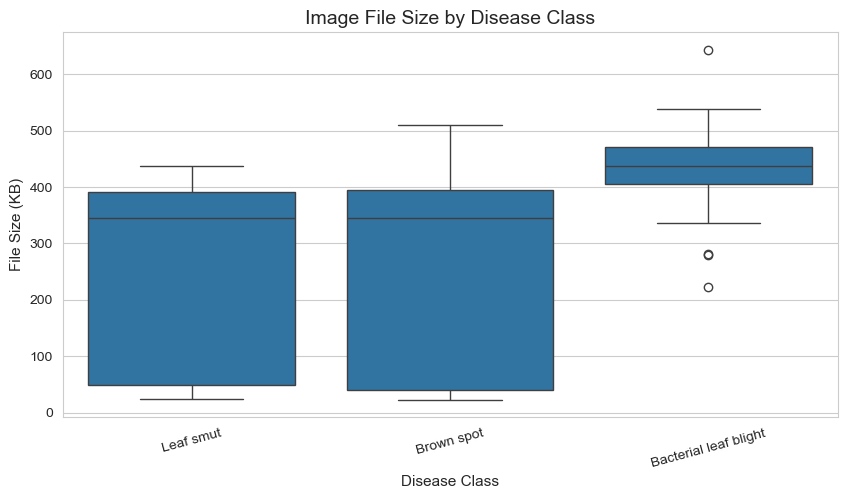

In [38]:

# ============================================
# CLASS-WISE FILE SIZE COMPARISON
# ============================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=image_metadata_df,
    x="Disease_Class",
    y="File_Size_KB"
)

plt.title("Image File Size by Disease Class")
plt.xlabel("Disease Class")
plt.ylabel("File Size (KB)")
plt.xticks(rotation=15)

plt.show()



### 6.6.1 Class-wise Image Quality Analysis – Findings

The class-wise image quality analysis was performed to identify variations in image dimensions, resolution, aspect ratio and file size across the three disease categories.

The following observations were identified:

**Bacterial Leaf Blight:**
- All 40 images have identical dimensions of 3081 × 897 pixels.
- The average image aspect ratio is 3.43.
- The images exhibit relatively consistent dimensions.

**Brown Spot:**
- The average image width is 1951.28 pixels.
- The average image height is 589.17 pixels.
- The average aspect ratio is 3.28.
- Considerable variation in image dimensions is observed.

**Leaf Smut:**
- The average image width is 2111.85 pixels.
- The average image height is 635.23 pixels.
- The average aspect ratio is 3.25.
- Image dimensions vary across the class.

**File Size Analysis:**

The file-size distribution indicates variations across disease categories. Brown Spot and Leaf Smut exhibit wider distributions, while Bacterial Leaf Blight has a relatively concentrated central distribution with some outliers.

**Potential Data Bias:**

The consistent dimensions of Bacterial Leaf Blight images, compared with the other two classes, indicate a potential dataset acquisition bias.

A classification model could potentially learn image acquisition characteristics instead of disease-specific visual patterns.

**Conclusion:**

Image dimensions and file-size variations across classes need to be considered during preprocessing and model evaluation. Standardized image preprocessing, visual inspection and careful validation will be used to reduce the risk of shortcut learning.


In [39]:

# ============================================
# DIMENSION CONSISTENCY BY DISEASE CLASS
# ============================================

dimension_analysis = (
    image_metadata_df
    .groupby("Disease_Class")
    .agg(
        Total_Images=("Image_Name", "count"),
        Unique_Widths=("Width", "nunique"),
        Unique_Heights=("Height", "nunique"),
        Unique_Dimensions=(
            "Image_Name",
            "count"
        )
    )
)

# Calculate the actual unique width-height combinations
unique_dimensions = (
    image_metadata_df
    .groupby("Disease_Class")
    .apply(
        lambda x: x[["Width", "Height"]]
        .drop_duplicates()
        .shape[0],
        include_groups=False
    )
)

dimension_analysis["Unique_Dimensions"] = unique_dimensions

display(dimension_analysis)


,Total_Images,Unique_Widths,Unique_Heights,Unique_Dimensions
Disease_Class,,,,
Bacterial leaf blight,40,1,1,1
Brown spot,40,20,20,20
Leaf smut,39,14,14,15



### 6.6.2 Image Dimension Consistency – Findings

The dimension consistency analysis revealed differences in image dimensions across the three disease categories.

The observations are:

1. Bacterial Leaf Blight contains 40 images with only one unique dimension combination (3081 × 897 pixels).

2. Brown Spot contains 20 unique dimension combinations across 40 images.

3. Leaf Smut contains 15 unique dimension combinations across 39 images.

These findings indicate that the image acquisition characteristics are not consistent across the three classes.

**Potential Modelling Risk:**

The model may learn image acquisition patterns instead of disease-specific characteristics. This could result in misleading classification performance.

**Proposed Solution:**

- Standardize all image dimensions.
- Preserve image aspect ratios during resizing.
- Apply suitable data augmentation.
- Evaluate model performance using an untouched test set.
- Examine prediction errors and model attention using Grad-CAM.

**Conclusion:**

Image dimension consistency is an important consideration for this dataset. Appropriate preprocessing and robust evaluation techniques will be used to improve model reliability.



## 6.7 Final Exploratory Data Analysis Summary

The Exploratory Data Analysis was performed to understand the structure, distribution and quality of the Rice Leaf Disease Detection dataset.

### Key Findings

1. The dataset contains 119 images instead of the expected 120 images.
2. The three disease classes are Bacterial Leaf Blight, Brown Spot and Leaf Smut.
3. Leaf Smut contains 39 images, while the other two classes contain 40 images each.
4. No corrupted images were detected.
5. All images are in RGB colour mode.
6. The dataset contains 34 unique image dimension combinations.
7. A significant number of images have dimensions of 3081 × 897 pixels.
8. The average image aspect ratio is 3.33.
9. No exact duplicate images were detected using MD5 hashing.
10. Image dimensions vary considerably across disease classes.
11. Bacterial Leaf Blight images exhibit identical dimensions, indicating potential image acquisition bias.
12. Visual inspection identified disease-related colour and texture patterns across the three classes.

### Data Quality Challenges Identified

| Challenge | Observation | Proposed Approach |
|---|---|---|
| Missing image | One fewer Leaf Smut image | Preserve original dataset |
| Varying dimensions | 34 unique dimensions | Image resizing |
| Aspect ratio variation | 1.25 to 5.30 | Preserve aspect ratio |
| Class-dependent dimensions | Different acquisition patterns | Investigate shortcut learning |
| Small dataset | Only 119 images | Transfer learning and augmentation |
| Potential visual similarities | Disease patterns may overlap | Error analysis and Grad-CAM |

### Overall Conclusion

The dataset is suitable for conducting an experimental three-class rice leaf disease classification study, subject to the identified limitations.

Image preprocessing, augmentation and transfer learning will be explored to develop a classification model.

The final model will be selected based on reliable validation and test performance rather than training accuracy alone.



# 7. DATA PREPROCESSING

Data preprocessing is an essential step in preparing image data for Deep Learning.

The original dataset contains images with different dimensions and three disease categories.

In this section, image paths and corresponding disease labels are organized into a structured dataset. The images are validated, labels are encoded, and the dataset is divided into training, validation and testing subsets.

The preprocessing pipeline is designed to maintain data integrity and prevent data leakage during model development.


In [41]:

# ============================================
# 7.2 LOAD IMAGE PATHS AND LABELS
# ============================================

import os
import pandas as pd
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

image_records = []

# Read each disease folder
for disease_folder in sorted(DISEASE_DIR.iterdir()):

    if disease_folder.is_dir():

        disease_label = disease_folder.name

        for image_path in disease_folder.rglob("*"):

            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMAGE_EXTENSIONS
            ):

                image_records.append({
                    "Image_Path": str(image_path),
                    "Disease_Class": disease_label,
                    "Image_Name": image_path.name
                })

# Create DataFrame
df = pd.DataFrame(image_records)

print("Dataset loaded successfully!")
print("Total images:", len(df))

display(df.head())


Dataset loaded successfully!
Total images: 119


,Image_Path,Disease_Class,Image_Name
0,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0365.JPG
1,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0366.jpg
2,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0367.JPG
3,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0370.jpg
4,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0372.JPG


In [42]:

# ============================================
# 7.3 IMAGE INTEGRITY VALIDATION
# ============================================

from PIL import Image

valid_records = []
invalid_records = []

for _, row in df.iterrows():

    image_path = row["Image_Path"]

    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_records.append(row.to_dict())

    except Exception as error:

        invalid_records.append({
            "Image_Path": image_path,
            "Error": str(error)
        })

# Retain only valid images
df = pd.DataFrame(valid_records)

print("IMAGE VALIDATION REPORT")
print("-" * 40)
print("Total image records:", len(image_records))
print("Valid images:", len(valid_records))
print("Invalid images:", len(invalid_records))

if invalid_records:
    display(pd.DataFrame(invalid_records))


IMAGE VALIDATION REPORT
----------------------------------------
Total image records: 119
Valid images: 119
Invalid images: 0


In [43]:

# ============================================
# 7.4 CLASS DISTRIBUTION VALIDATION
# ============================================

class_counts = df["Disease_Class"].value_counts().sort_index()

print("CLASS DISTRIBUTION")
print("-" * 40)

display(
    class_counts.rename_axis("Disease Class")
    .reset_index(name="Image Count")
)

print("Total images:", len(df))
print("Number of classes:", df["Disease_Class"].nunique())


CLASS DISTRIBUTION
----------------------------------------


,Disease Class,Image Count
0,Bacterial leaf blight,40
1,Brown spot,40
2,Leaf smut,39


Total images: 119
Number of classes: 3


In [44]:

# ============================================
# 7.5 LABEL ENCODING
# ============================================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["Encoded_Label"] = label_encoder.fit_transform(
    df["Disease_Class"]
)

# Display class mapping
class_mapping = {
    class_name: int(encoded_label)
    for class_name, encoded_label in zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
}

print("DISEASE LABEL ENCODING")
print("-" * 40)

for disease, label in class_mapping.items():
    print(f"{disease} : {label}")

display(df.head(10))


DISEASE LABEL ENCODING
----------------------------------------
Bacterial leaf blight : 0
Brown spot : 1
Leaf smut : 2


,Image_Path,Disease_Class,Image_Name,Encoded_Label
0,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0365.JPG,0
1,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0366.jpg,0
2,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0367.JPG,0
3,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0370.jpg,0
4,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0372.JPG,0
5,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0373.JPG,0
6,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0374.JPG,0
7,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0375.JPG,0
8,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0376.JPG,0
9,C:\Users\brind_0lf2fog\Capstone Project Datami...,Bacterial leaf blight,DSC_0377.JPG,0


In [45]:

# ============================================
# 7.6 FINAL DATASET CHECK
# ============================================

print("FINAL DATASET SUMMARY")
print("=" * 45)

print("Total images:", len(df))
print("Total disease classes:", df["Encoded_Label"].nunique())
print("Missing values:\n", df.isnull().sum())

print("\nEncoded class distribution:")

display(
    df.groupby(["Disease_Class", "Encoded_Label"])
      .size()
      .reset_index(name="Image_Count")
)

print("\nDataset preparation completed successfully!")


FINAL DATASET SUMMARY
Total images: 119
Total disease classes: 3
Missing values:
 Image_Path       0
Disease_Class    0
Image_Name       0
Encoded_Label    0
dtype: int64

Encoded class distribution:


,Disease_Class,Encoded_Label,Image_Count
0,Bacterial leaf blight,0,40
1,Brown spot,1,40
2,Leaf smut,2,39



Dataset preparation completed successfully!



### 7.7 Data Loading and Validation – Findings

The dataset was successfully loaded into a structured Pandas DataFrame.

The following results were obtained:

- Total images loaded: 119
- Valid images: 119
- Invalid images: 0
- Number of disease classes: 3
- Missing values: 0

Label encoding was performed using Scikit-learn's LabelEncoder.

The class mapping is:

- Bacterial Leaf Blight: 0
- Brown Spot: 1
- Leaf Smut: 2

All image records were successfully validated, and the dataset is ready for stratified data partitioning.

**Conclusion:**

The image loading, integrity validation and label encoding processes were completed successfully. The dataset is now structured for supervised multi-class image classification.


In [46]:

# ============================================
# 7.8 TRAIN, VALIDATION AND TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# First: Separate the final test set (15%)
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["Encoded_Label"]
)

# Second: Separate validation set (15% of total)
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_val_df["Encoded_Label"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("DATA SPLITTING COMPLETED")
print("-" * 45)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))


DATA SPLITTING COMPLETED
---------------------------------------------
Training images: 83
Validation images: 18
Testing images: 18
Total images: 119


In [47]:

# ============================================
# VERIFY STRATIFIED DISTRIBUTION
# ============================================

split_summary = pd.DataFrame({
    "Training": train_df["Disease_Class"].value_counts(),
    "Validation": val_df["Disease_Class"].value_counts(),
    "Testing": test_df["Disease_Class"].value_counts()
}).fillna(0).astype(int)

display(split_summary)

print("\nPercentage distribution:")

percentage_summary = (
    split_summary.div(split_summary.sum(axis=0), axis=1) * 100
).round(2)

display(percentage_summary)


,Training,Validation,Testing
Disease_Class,,,
Bacterial leaf blight,28,6,6
Brown spot,28,6,6
Leaf smut,27,6,6



Percentage distribution:


,Training,Validation,Testing
Disease_Class,,,
Bacterial leaf blight,33.73,33.33,33.33
Brown spot,33.73,33.33,33.33
Leaf smut,32.53,33.33,33.33


In [48]:

# ============================================
# DATA LEAKAGE CHECK
# ============================================

train_paths = set(train_df["Image_Path"])
val_paths = set(val_df["Image_Path"])
test_paths = set(test_df["Image_Path"])

print("Train-Validation overlap:", len(train_paths & val_paths))
print("Train-Test overlap:", len(train_paths & test_paths))
print("Validation-Test overlap:", len(val_paths & test_paths))

assert len(train_paths & val_paths) == 0
assert len(train_paths & test_paths) == 0
assert len(val_paths & test_paths) == 0

print("\nNo image overlap detected!")


Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

No image overlap detected!


In [49]:

# ============================================
# SAVE DATASET SPLITS
# ============================================

train_df.to_csv(
    PROJECT_DIR / "train_dataset.csv",
    index=False
)

val_df.to_csv(
    PROJECT_DIR / "validation_dataset.csv",
    index=False
)

test_df.to_csv(
    PROJECT_DIR / "test_dataset.csv",
    index=False
)

print("All dataset splits saved successfully!")


All dataset splits saved successfully!



### 7.8.1 Train, Validation and Test Split – Findings

The dataset was divided into three subsets using stratified sampling.

The splitting strategy was:

- Training: 70%
- Validation: 15%
- Testing: 15%

The resulting dataset distribution is:

| Disease Class | Training | Validation | Testing |
|---|---:|---:|---:|
| Bacterial Leaf Blight | 28 | 6 | 6 |
| Brown Spot | 28 | 6 | 6 |
| Leaf Smut | 27 | 6 | 6 |
| Total | 83 | 18 | 18 |

Stratified sampling was used to maintain proportional class representation across all three subsets.

A data leakage check was performed using image file paths.

The results confirmed:

- Training and validation overlap: 0
- Training and testing overlap: 0
- Validation and testing overlap: 0

**Conclusion:**

The dataset was successfully divided into training, validation and testing subsets. No overlapping image paths were identified between the subsets.

The training dataset will be used for model development, validation data for model tuning, and the test dataset will remain untouched until final evaluation.

Due to the limited number of test images, cross-validation will also be considered during model comparison.



## 7.9 Image Resizing and Normalization

Image preprocessing is performed to convert the original rice leaf images into a consistent format suitable for CNN architectures.

The original dataset contains images with varying dimensions and aspect ratios.

The following preprocessing techniques are applied:

1. Resize images to a standard input size of 224 × 224 pixels.
2. Preserve the original aspect ratio to minimize image distortion.
3. Apply padding to obtain uniform image dimensions.
4. Convert images into RGB format.
5. Normalize pixel values to the range [0, 1].

These operations ensure consistent image input dimensions while preserving important visual characteristics of rice leaf diseases.


In [80]:

# ============================================
# IMAGE RESIZING AND NORMALIZATION
# ============================================

from PIL import ImageOps
import numpy as np

IMG_SIZE = (224, 224)

def preprocess_image(image_path):

    # Open image
    with Image.open(image_path) as img:

        # Convert to RGB
        img = img.convert("RGB")

        # Preserve aspect ratio and resize
        img.thumbnail(IMG_SIZE, Image.Resampling.LANCZOS)

        # Create square canvas
        canvas = Image.new("RGB", IMG_SIZE, color=(255, 255, 255))

        # Center image on canvas
        x_offset = (IMG_SIZE[0] - img.width) // 2
        y_offset = (IMG_SIZE[1] - img.height) // 2

        canvas.paste(img, (x_offset, y_offset))

        # Convert to NumPy array
        image_array = np.asarray(canvas, dtype=np.float32)

        # Normalize pixels
        image_array = image_array / 255.0

        return image_array

print("Image preprocessing function created!")


Image preprocessing function created!


In [52]:

# Select one sample image
sample_path = train_df.iloc[0]["Image_Path"]

processed_image = preprocess_image(sample_path)

print("Original image path:", sample_path)
print("Processed image shape:", processed_image.shape)
print("Minimum pixel value:", processed_image.min())
print("Maximum pixel value:", processed_image.max())


Original image path: C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\dataset\RiceLeaf_Images\Leaf smut\Leaf smut\DSC_0314.JPG
Processed image shape: (224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


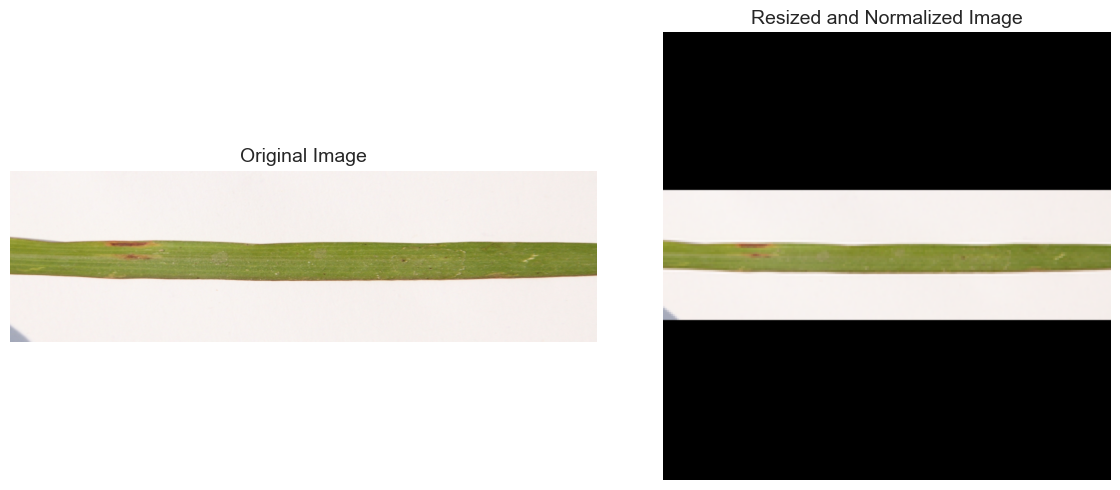

In [53]:

# ============================================
# ORIGINAL VS PROCESSED IMAGE
# ============================================

with Image.open(sample_path) as img:
    original_image = img.convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title("Resized and Normalized Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


### 7.9 Image Resizing and Normalization

All images were converted to RGB format and resized to 224 × 224 pixels while preserving their original aspect ratio. Padding was added to maintain the image dimensions without distorting the leaf structure.

Pixel values were normalized from the original range of 0–255 to 0–1.

The preprocessing output was validated to confirm:
- Consistent image dimensions of 224 × 224 × 3.
- Three RGB color channels.
- Pixel values within the range of 0–1.

**Observation:** Since the original images have a wide aspect ratio, padding is introduced during resizing. The impact of this approach on disease-feature visibility and model performance will be evaluated during model experimentation.

## 7.10 Creating TensorFlow Image Datasets

The training, validation, and test datasets are converted into TensorFlow datasets using `tf.data.Dataset`.

A batch size of 8 is selected to support efficient training in a CPU-based environment.

The training dataset is shuffled to reduce ordering bias. Validation and test datasets are kept unshuffled and are not subjected to data augmentation at this stage.

The original stratified split and disease-class labels are preserved.

In [54]:
# Define dataset configuration
BATCH_SIZE = 8
NUM_CLASSES = len(label_encoder.classes_)

# Display class names and their encoded labels
class_names = label_encoder.classes_.tolist()

print("Class mapping:")
for index, class_name in enumerate(class_names):
    print(f"{index}: {class_name}")


# Function to create TensorFlow datasets
def create_tf_dataset(data_frame, batch_size=8, shuffle=False):

    data_frame = data_frame.reset_index(drop=True).copy()

    def data_generator():
        for _, row in data_frame.iterrows():

            image = preprocess_image(row["Image_Path"])
            label = np.int32(row["Encoded_Label"])

            yield image, label

    dataset = tf.data.Dataset.from_generator(
        data_generator,
        output_signature=(
            tf.TensorSpec(
                shape=(224, 224, 3),
                dtype=tf.float32
            ),
            tf.TensorSpec(
                shape=(),
                dtype=tf.int32
            )
        )
    )

    # Shuffle only the training dataset
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(data_frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    # Create batches
    dataset = dataset.batch(batch_size)

    # Prefetch for efficient data loading
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create training, validation and test datasets
train_ds = create_tf_dataset(
    train_df,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = create_tf_dataset(
    val_df,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = create_tf_dataset(
    test_df,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nTensorFlow datasets created successfully!")

Class mapping:
0: Bacterial leaf blight
1: Brown spot
2: Leaf smut

TensorFlow datasets created successfully!


In [56]:
# Count batches manually
train_batches = sum(1 for _ in train_ds)
val_batches = sum(1 for _ in val_ds)
test_batches = sum(1 for _ in test_ds)

print("Number of training batches:", train_batches)
print("Number of validation batches:", val_batches)
print("Number of test batches:", test_batches)

print("\nDataset image counts:")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Number of training batches: 11
Number of validation batches: 3
Number of test batches: 3

Dataset image counts:
Training images: 83
Validation images: 18
Test images: 18


## 8. CNN Model Development

### 8.1 Baseline Convolutional Neural Network

A baseline CNN model is developed to classify rice leaf images into three disease categories:

1. Bacterial leaf blight
2. Brown spot
3. Leaf smut

The architecture consists of convolutional layers, max-pooling layers, global average pooling, dropout regularization and a softmax output layer.

The baseline model establishes a performance benchmark before experimenting with data augmentation and alternative architectures.

In [59]:
# Define baseline CNN architecture

from tensorflow.keras import layers, models

baseline_cnn = models.Sequential([

    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Regularization
    layers.Dropout(0.4),

    # Classification layer
    layers.Dense(3, activation="softmax")
])

# Compile the model
baseline_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN model created successfully!")

Baseline CNN model created successfully!


In [60]:
baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,635 (365.76 KB)

 Trainable params: 93,635 (365.76 KB)

 Non-trainable params: 0 (0.00 B)

### 8.2 Training Configuration and Callbacks

Three callbacks are configured to improve training efficiency and reduce overfitting.

1. EarlyStopping monitors validation loss and stops training when no improvement is observed.
2. ModelCheckpoint saves the model with the lowest validation loss.
3. ReduceLROnPlateau reduces the learning rate when validation loss stops improving.

The maximum number of epochs is initially set to 30. Early stopping may terminate training before this limit.

In [61]:
# Create model directory if it does not exist
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(MODEL_DIR / "baseline_cnn_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

EPOCHS = 30

print("Training callbacks configured successfully!")
print("Maximum epochs:", EPOCHS)

Training callbacks configured successfully!
Maximum epochs: 30


In [64]:
history = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
     11/Unknown 18s 696ms/step - accuracy: 0.8072 - loss: 0.5092
Epoch 1: val_loss improved from 0.67232 to 0.63098, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\baseline_cnn_best.keras

Epoch 1: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\baseline_cnn_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 897ms/step - accuracy: 0.8072 - loss: 0.5092 - val_accuracy: 0.7222 - val_loss: 0.6310 - learning_rate: 5.0000e-04
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - accuracy: 0.7711 - loss: 0.4944
Epoch 2: val_loss did not improve from 0.63098
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 818ms/step - accuracy: 0.7711 - loss: 0.4944 - val_accuracy: 0.6111 - val_loss: 0.6995 - learning_rate: 5.0000e-04
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 599ms/step - accuracy: 0.7952 - loss: 0.5066
Epoch 3: val_loss did not improve from 0.63098
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 815ms/step

### 8.4 Learning Curve Analysis

Learning curves are plotted to understand how the CNN performs during training.

Training and validation accuracy are compared to evaluate learning progress and generalization.

Training and validation loss are compared to identify possible overfitting, underfitting or unstable learning behaviour.

In [ ]:
import matplotlib.pyplot as plt

# Extract training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Create accuracy plot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation Accuracy")
plt.title("Baseline CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Create loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.title("Baseline CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [65]:
def build_baseline_cnn():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(32, (3, 3),
                      activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3),
                      activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3),
                      activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dropout(0.4),

        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Create a completely fresh model
baseline_cnn = build_baseline_cnn()

print("Fresh baseline CNN created!")

Fresh baseline CNN created!


In [66]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(MODEL_DIR / "baseline_cnn_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

In [67]:
history = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
     11/Unknown 48s 685ms/step - accuracy: 0.3133 - loss: 1.1280
Epoch 1: val_loss improved from None to 1.09862, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\baseline_cnn_best.keras

Epoch 1: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\baseline_cnn_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.3133 - loss: 1.1280 - val_accuracy: 0.3333 - val_loss: 1.0986 - learning_rate: 0.0010
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 658ms/step - accuracy: 0.3614 - loss: 1.0951
Epoch 2: val_loss improved from 1.09862 to 1.09751, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\baseline_cnn_best.keras

Epoch 2: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\baseline_cnn_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 903ms/step - accuracy

### 8.3 Clean Baseline CNN Training Results

A fresh baseline CNN was trained using newly initialized weights,
a fresh Adam optimizer and independently configured callbacks.

The model was trained for 30 epochs.

**Training Performance**
- Training Accuracy: 63.86%
- Training Loss: 0.8454

**Validation Performance**
- Validation Accuracy: 44.44%
- Validation Loss: 0.9344

**Observations**

1. The model learned patterns from the training images.
2. Validation performance remained relatively low.
3. The difference between training and validation performance
   indicates limited generalization.
4. The best validation loss was recorded at epoch 30.
5. Early stopping was not triggered.

This experiment establishes the clean baseline for comparison
with subsequent CNN and transfer learning experiments.

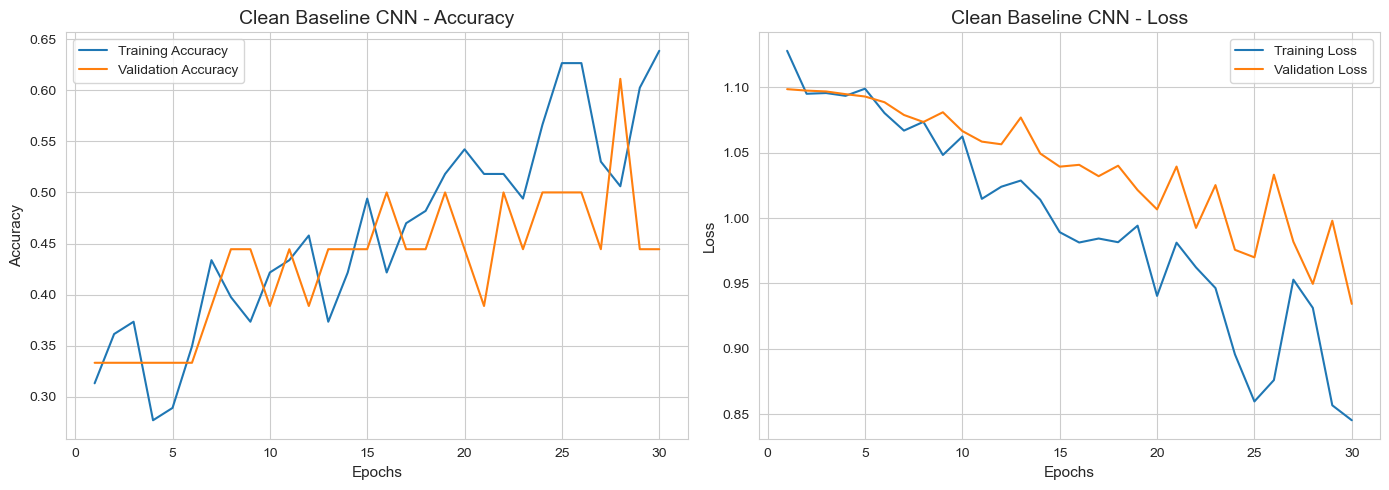

In [69]:
import matplotlib.pyplot as plt

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation Accuracy")
plt.title("Clean Baseline CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.title("Clean Baseline CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 8.4 Learning Curve Analysis and Interpretation

The training and validation accuracy and loss curves were
visualized to understand the learning behaviour of the baseline CNN.

**Accuracy Analysis:**
- Training accuracy increased throughout the training process.
- Validation accuracy fluctuated considerably.
- The highest validation accuracy was approximately 61.11%.
- Final validation accuracy was 44.44%.

**Loss Analysis:**
- Training loss decreased from approximately 1.13 to 0.85.
- Validation loss decreased from approximately 1.10 to 0.93.
- The validation loss showed an overall downward trend.

**Key Findings:**

1. The CNN successfully learned patterns from training images.
2. Validation performance was unstable.
3. A generalization gap was observed between training and validation.
4. The small validation dataset contributes to metric variability.

**Conclusion:**

The baseline CNN provides a benchmark for subsequent experiments.
Data augmentation will be investigated to improve generalization
and reduce sensitivity to variations in image appearance.

## 9. Data Augmentation

### 9.2 Implementing Data Augmentation

Data augmentation introduces controlled variations
to improve model generalization.

In [72]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal", seed=42),
    layers.RandomRotation(0.05, seed=42),
    layers.RandomZoom(0.10, seed=42),
    layers.RandomContrast(0.10, seed=42)
], name="data_augmentation")

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


### 9.3 Visualization of Augmented Images

A sample of training images is selected and passed through the data augmentation pipeline.

The original and augmented images are compared visually to verify that the transformations introduce realistic variations without removing important disease characteristics.

This validation helps ensure that augmentation does not distort the visual patterns required for disease classification.

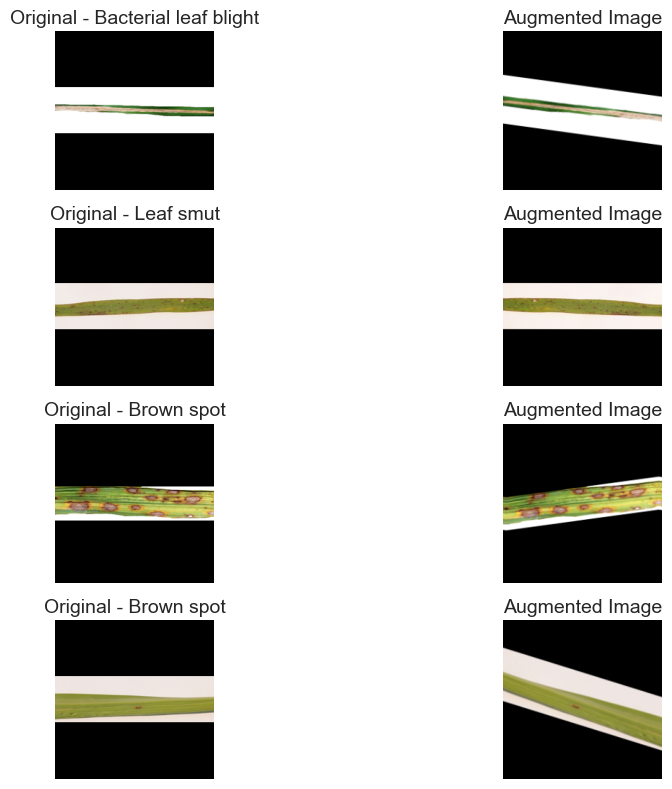

In [73]:
# Get one batch of training images
for images, labels in train_ds.take(1):
    sample_images = images[:4]
    sample_labels = labels[:4]

# Apply augmentation
augmented_images = data_augmentation(
    sample_images,
    training=True
)

# Visualize original and augmented images
plt.figure(figsize=(12, 8))

for i in range(4):

    # Original image
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(sample_images[i].numpy())
    plt.title(
        f"Original - {class_names[sample_labels[i].numpy()]}"
    )
    plt.axis("off")

    # Augmented image
    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(
        tf.clip_by_value(
            augmented_images[i],
            0,
            1
        ).numpy()
    )
    plt.title("Augmented Image")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [81]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        mode="horizontal",
        seed=42
    ),

    layers.RandomRotation(
        factor=0.02,
        fill_mode="reflect",
        seed=42
    ),

    layers.RandomZoom(
        height_factor=0.05,
        width_factor=0.05,
        seed=42
    ),

    layers.RandomContrast(
        factor=0.10,
        seed=42
    )

], name="data_augmentation")

print("Improved augmentation pipeline created!")

Improved augmentation pipeline created!


In [82]:
train_ds = create_tf_dataset(
    train_df,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = create_tf_dataset(
    val_df,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = create_tf_dataset(
    test_df,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Datasets recreated using white padding!")

Datasets recreated using white padding!


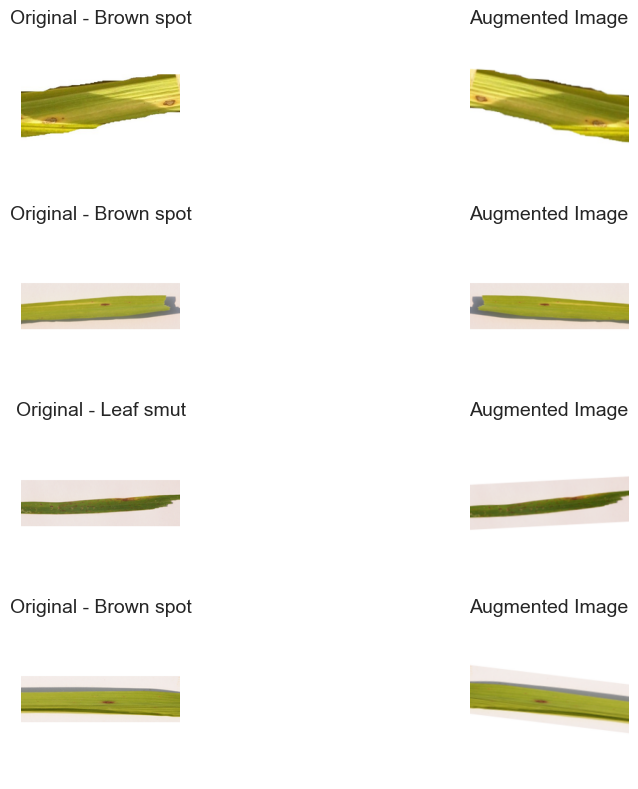

In [83]:
# Get one batch of training images
for images, labels in train_ds.take(1):
    sample_images = images[:4]
    sample_labels = labels[:4]

# Apply improved augmentation
augmented_images = data_augmentation(
    sample_images,
    training=True
)

# Display original and augmented images
plt.figure(figsize=(12, 8))

for i in range(4):

    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(sample_images[i].numpy())
    plt.title(
        f"Original - {class_names[sample_labels[i].numpy()]}"
    )
    plt.axis("off")

    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(
        tf.clip_by_value(
            augmented_images[i], 0, 1
        ).numpy()
    )
    plt.title("Augmented Image")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 9.5 Building CNN with Data Augmentation

A second CNN model is developed by integrating the data augmentation
pipeline into the baseline CNN architecture.

The same convolutional architecture is retained to isolate the
effect of data augmentation on model performance.

Augmentation layers are active only during training and remain
inactive during validation and inference.

In [84]:
# Build CNN model with data augmentation

augmented_cnn = models.Sequential([

    # Input
    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(32, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Regularization
    layers.Dropout(0.4),

    # Output
    layers.Dense(3, activation="softmax")

])

# Compile model
augmented_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN model created successfully!")

Augmented CNN model created successfully!


In [85]:
augmented_cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,635 (365.76 KB)

 Trainable params: 93,635 (365.76 KB)

 Non-trainable params: 0 (0.00 B)

In [86]:
augmented_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "augmented_cnn_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

In [87]:
augmented_history = augmented_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=augmented_callbacks,
    verbose=1
)

Epoch 1/30
     11/Unknown 14s 732ms/step - accuracy: 0.2530 - loss: 1.1817
Epoch 1: val_loss improved from None to 1.10257, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\augmented_cnn_best.keras

Epoch 1: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\augmented_cnn_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.2530 - loss: 1.1817 - val_accuracy: 0.3333 - val_loss: 1.1026 - learning_rate: 0.0010
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 548ms/step - accuracy: 0.3494 - loss: 1.1009
Epoch 2: val_loss improved from 1.10257 to 1.09867, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\augmented_cnn_best.keras

Epoch 2: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\augmented_cnn_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 711ms/step - accu

### 9.5 Augmented CNN Training Results

The augmented CNN was trained for 30 epochs using the
training dataset with dynamic image augmentation.

**Training Performance**
- Training Accuracy: 62.65%
- Training Loss: 0.8340

**Validation Performance**
- Validation Accuracy: 44.44%
- Validation Loss: 0.9549

**Observations**

1. The model learned patterns from augmented training images.
2. Validation accuracy remained unchanged compared with the
   clean baseline CNN.
3. Validation loss was slightly higher than the baseline.
4. The experiment did not demonstrate an improvement in
   validation performance.

**Experimental Limitation**

The image padding strategy was changed from black to white
between the baseline and augmented experiments. Therefore,
the observed performance difference cannot be attributed
to augmentation alone.

A controlled experiment with identical preprocessing will
be required for a fair comparison.

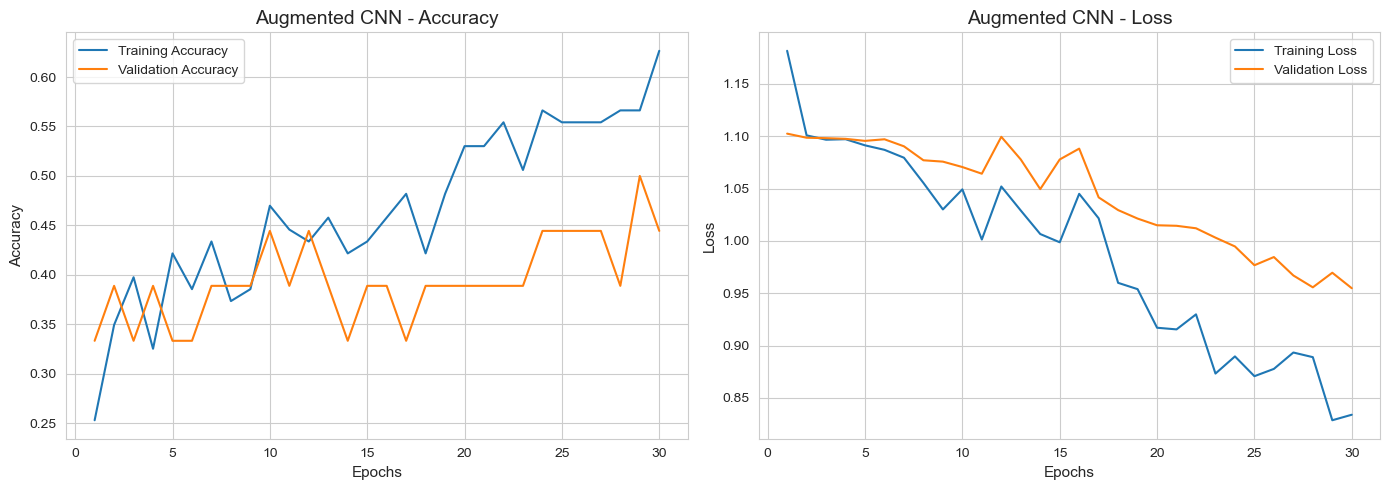

In [88]:
# Extract augmented CNN training history

aug_train_accuracy = augmented_history.history["accuracy"]
aug_val_accuracy = augmented_history.history["val_accuracy"]

aug_train_loss = augmented_history.history["loss"]
aug_val_loss = augmented_history.history["val_loss"]

epochs_range = range(1, len(aug_train_accuracy) + 1)

# Plot learning curves
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    aug_train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    aug_val_accuracy,
    label="Validation Accuracy"
)

plt.title("Augmented CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    aug_train_loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    aug_val_loss,
    label="Validation Loss"
)

plt.title("Augmented CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 9.6 Augmented CNN Learning Curve Analysis

The training and validation accuracy and loss curves were
analysed to understand the impact of data augmentation.

**Accuracy Analysis**
- Training accuracy increased from approximately 25% to 63%.
- Validation accuracy fluctuated between 33.33% and 50%.
- Best validation accuracy was 50%.
- Final validation accuracy was 44.44%.

**Loss Analysis**
- Training loss decreased from approximately 1.18 to 0.83.
- Validation loss decreased from approximately 1.10 to 0.95.
- A generalization gap was observed between training and
  validation loss.

**Conclusion**

Data augmentation helped the model learn from transformed
training images. However, validation performance did not
improve over the baseline CNN.

Further experiments using transfer learning will be conducted
to investigate whether pretrained image features improve
classification performance.

In [90]:
try:
    mobilenet_base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )

    print("MobileNetV2 pretrained weights downloaded successfully!")
    print("Number of layers:", len(mobilenet_base.layers))

except Exception as e:
    print("MobileNetV2 initialization failed.")
    print("Error:", e)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 pretrained weights downloaded successfully!
Number of layers: 154


### 10.3 MobileNetV2 Transfer Learning

MobileNetV2 is selected as the first transfer learning architecture.

The model uses pretrained ImageNet weights to extract general
visual features.

The original classification head is removed using
`include_top=False`.

Initially, the pretrained convolutional layers will be frozen
to preserve learned features. A new classification head will
be trained for the three rice leaf disease categories.

MobileNetV2-specific preprocessing will transform pixel values
from the range [0, 1] to [-1, 1].

In [92]:
# Freeze pretrained MobileNetV2 layers

mobilenet_base.trainable = False

print("Total layers:", len(mobilenet_base.layers))
print("Trainable:", mobilenet_base.trainable)

print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in mobilenet_base.trainable_weights))

print("Non-trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in mobilenet_base.non_trainable_weights))

Total layers: 154
Trainable: False
Trainable parameters: 0
Non-trainable parameters: 2257984


In [93]:
# Convert image values from [0, 1] to [-1, 1]

def mobilenet_preprocessing(images, labels):

    images = tf.keras.applications.mobilenet_v2.preprocess_input(
        images * 255.0
    )

    return images, labels


# Apply preprocessing to all datasets
mobilenet_train_ds = train_ds.map(
    mobilenet_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

mobilenet_val_ds = val_ds.map(
    mobilenet_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

mobilenet_test_ds = test_ds.map(
    mobilenet_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("MobileNetV2 preprocessing completed!")

MobileNetV2 preprocessing completed!


In [94]:
for images, labels in mobilenet_train_ds.take(1):

    print("Image shape:", images.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

Image shape: (8, 224, 224, 3)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


### 10.4 Building the MobileNetV2 Classification Model

The pretrained MobileNetV2 backbone is connected to a custom
classification head for rice leaf disease classification.

Global Average Pooling is used to reduce the extracted feature
maps into a compact feature vector.

A dropout layer is added to reduce overfitting.

The final Dense layer contains three neurons with softmax
activation to predict the three rice leaf disease classes.

The pretrained backbone remains frozen during initial training.

In [96]:
# Build MobileNetV2 transfer learning model

mobilenet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Pretrained feature extractor
    mobilenet_base,

    # Convert feature maps into a feature vector
    layers.GlobalAveragePooling2D(),

    # Regularization
    layers.Dropout(0.3),

    # Three-class classification
    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )

], name="MobileNetV2_Rice_Disease")

# Compile model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 classification model created!")

MobileNetV2 classification model created!


In [97]:
mobilenet_model.summary()

Model: "MobileNetV2_Rice_Disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [99]:
mobilenet_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "mobilenetv2_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

In [100]:
mobilenet_history = mobilenet_model.fit(
    mobilenet_train_ds,
    validation_data=mobilenet_val_ds,
    epochs=30,
    callbacks=mobilenet_callbacks,
    verbose=1
)

Epoch 1/30
     11/Unknown 20s 308ms/step - accuracy: 0.3373 - loss: 1.3703
Epoch 1: val_loss improved from None to 1.23335, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_best.keras

Epoch 1: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 25s 869ms/step - accuracy: 0.3373 - loss: 1.3703 - val_accuracy: 0.3333 - val_loss: 1.2333 - learning_rate: 1.0000e-04
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step - accuracy: 0.3976 - loss: 1.2483
Epoch 2: val_loss improved from 1.23335 to 1.19303, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_best.keras

Epoch 2: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 494ms/step - accura

### 10.4 MobileNetV2 Training Results

The MobileNetV2 transfer learning model was trained for
30 epochs with its pretrained backbone frozen.

**Training Performance**
- Training Accuracy: 72.29%
- Training Loss: 0.5762

**Validation Performance**
- Validation Accuracy: 83.33%
- Validation Loss: 0.7435

**Model Configuration**
- Total Parameters: 2,261,827
- Trainable Parameters: 3,843
- Non-trainable Parameters: 2,257,984

**Key Observations**

1. The pretrained MobileNetV2 architecture successfully
   learned useful features for rice leaf classification.
2. Validation accuracy reached 83.33%.
3. Validation accuracy was higher than training accuracy.
4. The best validation loss was recorded at epoch 30.
5. Early stopping was not triggered.

**Conclusion**

MobileNetV2 demonstrates promising validation performance
and currently outperforms the baseline CNN and augmented CNN.

However, the small validation dataset and differences in
preprocessing must be considered before making a final
model selection.

### 10.5 MobileNetV2 Learning Curve Analysis

Training and validation accuracy and loss curves are
visualized to evaluate the learning behaviour of MobileNetV2.

The plots help identify learning progress, convergence,
instability and possible overfitting.

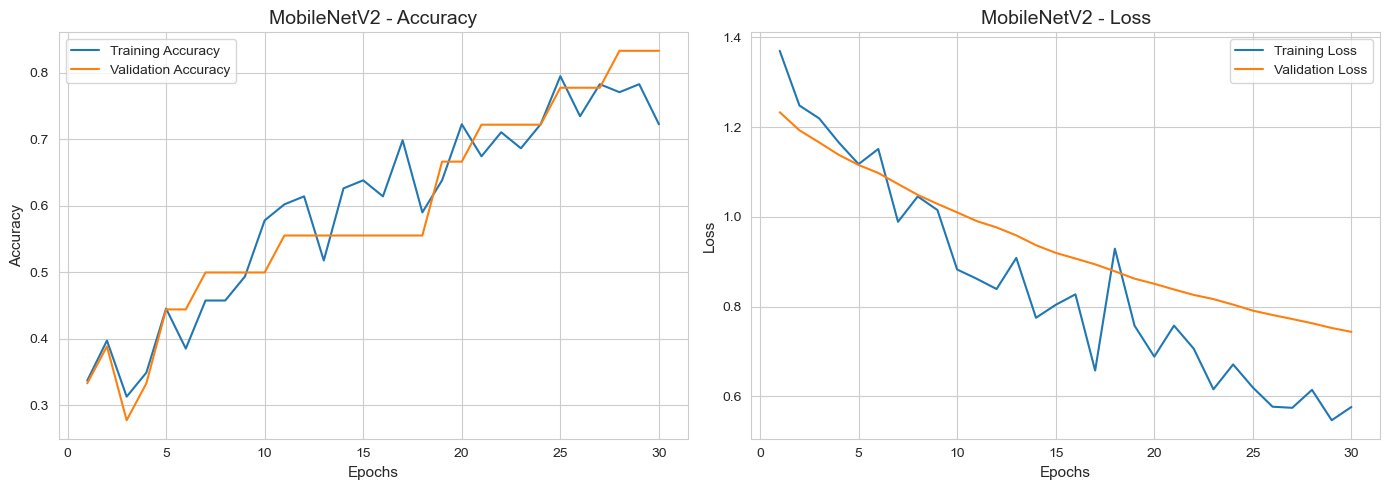

In [101]:
# Extract MobileNetV2 training history

mobile_train_accuracy = mobilenet_history.history["accuracy"]
mobile_val_accuracy = mobilenet_history.history["val_accuracy"]

mobile_train_loss = mobilenet_history.history["loss"]
mobile_val_loss = mobilenet_history.history["val_loss"]

epochs_range = range(1, len(mobile_train_accuracy) + 1)

# Plot accuracy and loss
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    mobile_train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    mobile_val_accuracy,
    label="Validation Accuracy"
)

plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    mobile_train_loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    mobile_val_loss,
    label="Validation Loss"
)

plt.title("MobileNetV2 - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [102]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUTPUT_DIR / "mobilenetv2_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1000x600 with 0 Axes>

### 10.5 MobileNetV2 Learning Curve Analysis

The MobileNetV2 learning curves indicate a consistent improvement in model performance over 30 epochs.

**Accuracy observations:**
- Training accuracy increased to approximately 72.29%.
- Validation accuracy reached 83.33%.
- Validation accuracy improved over the training period and remained stable during the final epochs.

**Loss observations:**
- Training loss decreased to approximately 0.5762.
- Validation loss decreased to approximately 0.7435.
- Both loss curves show a downward trend, indicating that the model continued learning throughout training.

**Interpretation:**

The decreasing training and validation losses suggest that MobileNetV2 is learning meaningful image representations. The validation accuracy being higher than training accuracy may be partly explained by dropout being active during training and inactive during validation.

No strong evidence of severe overfitting is visible in the learning curves. However, the validation dataset contains only 18 images, so the result should be interpreted cautiously.

**Conclusion:**

MobileNetV2 achieved the best validation performance among the three models evaluated so far. Its transfer-learning approach appears promising for rice leaf disease classification. Final performance must be assessed using the independent test dataset.

In [103]:
# Evaluate MobileNetV2 on the untouched test dataset

mobile_test_loss, mobile_test_accuracy = mobilenet_model.evaluate(
    mobilenet_test_ds,
    verbose=1
)

print(f"MobileNetV2 Test Loss: {mobile_test_loss:.4f}")
print(f"MobileNetV2 Test Accuracy: {mobile_test_accuracy:.4f}")
print(f"MobileNetV2 Test Accuracy (%): {mobile_test_accuracy * 100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6667 - loss: 0.6768
MobileNetV2 Test Loss: 0.6768
MobileNetV2 Test Accuracy: 0.6667
MobileNetV2 Test Accuracy (%): 66.67%


### 10.6 MobileNetV2 – Confusion Matrix and Classification Report

A confusion matrix is used to evaluate the classification performance of the model by comparing actual disease labels with predicted disease labels.

The classification report provides class-wise precision, recall, F1-score, and support.

These metrics help identify whether the model performs consistently across all three rice leaf disease categories rather than relying only on overall accuracy.

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step


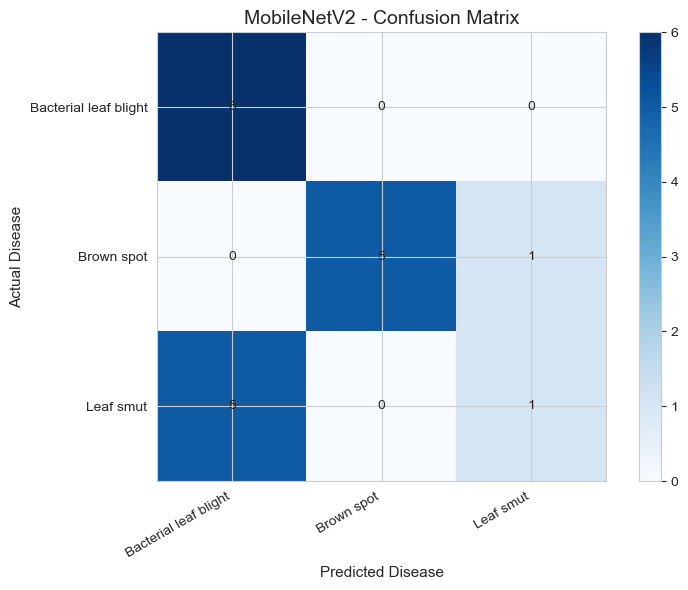

MobileNetV2 Classification Report
                       precision    recall  f1-score   support

Bacterial leaf blight       0.55      1.00      0.71         6
           Brown spot       1.00      0.83      0.91         6
            Leaf smut       0.50      0.17      0.25         6

             accuracy                           0.67        18
            macro avg       0.68      0.67      0.62        18
         weighted avg       0.68      0.67      0.62        18



In [104]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

# Collect actual labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in mobilenet_test_ds
])

# Generate model predictions
y_prob = mobilenet_model.predict(mobilenet_test_ds, verbose=1)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_prob, axis=1)

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Display confusion matrix
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("MobileNetV2 - Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(NUM_CLASSES)
plt.xticks(tick_marks, class_names, rotation=30, ha="right")
plt.yticks(tick_marks, class_names)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.tight_layout()
plt.show()

# Classification report
print("MobileNetV2 Classification Report")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )
)

### 10.8 MobileNetV2 – Classification Report Analysis

The classification report provides a detailed evaluation of MobileNetV2 across all three rice leaf disease classes.

**Overall performance:**
- Accuracy: 66.67%
- Macro average precision: 0.68
- Macro average recall: 0.67
- Macro average F1-score: 0.62
- Weighted average F1-score: 0.62

**Class-wise findings:**

1. Bacterial leaf blight achieved 100% recall, indicating that all six actual test images were identified correctly. However, its precision was 54.55%, because several images from other classes were incorrectly predicted as this disease.
2. Brown spot achieved the best classification performance, with an F1-score of 0.91.
3. Leaf smut achieved only 16.67% recall and an F1-score of 0.25. Five out of six actual Leaf smut images were misclassified as Bacterial leaf blight.

**Conclusion:**

Although MobileNetV2 achieved 66.67% test accuracy, its class-wise performance is inconsistent. The low recall for Leaf smut is a major limitation. Further investigation and experimentation are required before selecting the final model.

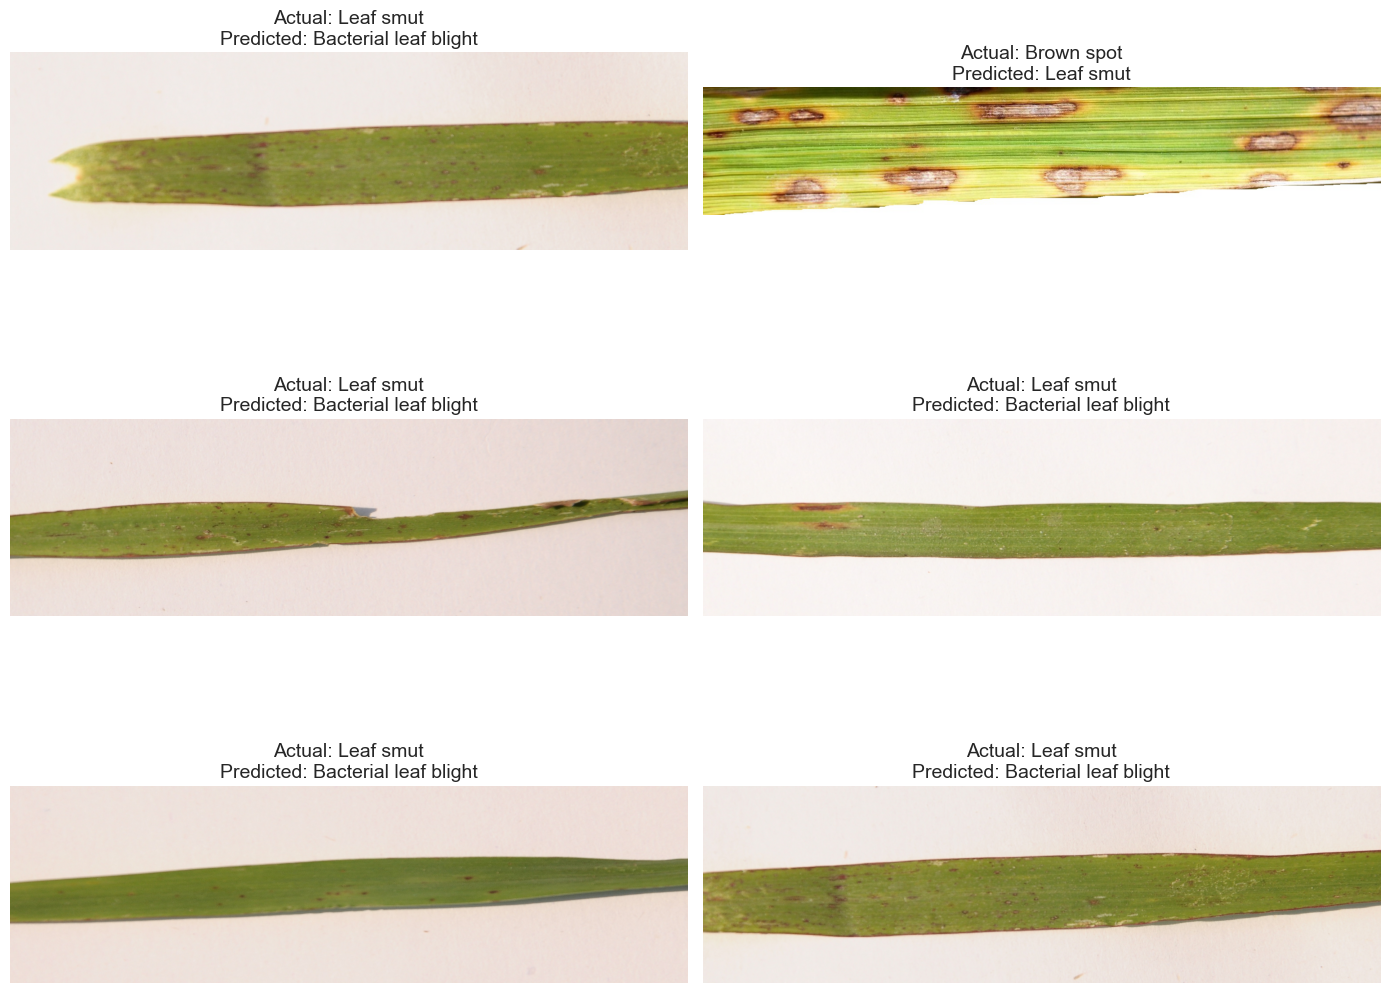

In [105]:
from PIL import Image
import matplotlib.pyplot as plt
import math

misclassified_indices = np.where(y_true != y_pred)[0]

cols = 2
rows = math.ceil(len(misclassified_indices) / cols)

plt.figure(figsize=(14, rows * 4))

for plot_num, idx in enumerate(misclassified_indices, 1):

    image_path = test_df.iloc[idx]["Image_Path"]
    image = Image.open(image_path).convert("RGB")

    actual = class_names[y_true[idx]]
    predicted = class_names[y_pred[idx]]

    plt.subplot(rows, cols, plot_num)
    plt.imshow(image)
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 10.9 Visual Investigation of Misclassified Images

The misclassified test images were visually examined to understand the classification errors made by MobileNetV2.

**Observations:**

- Five actual Leaf smut images were incorrectly classified as Bacterial leaf blight.
- One actual Brown spot image was incorrectly classified as Leaf smut.
- Several Leaf smut images contain relatively subtle and scattered visible marks.
- The disease symptoms occupy a small portion of the complete leaf image.
- The long horizontal leaf structure and white background are common visual characteristics across several images.

**Possible explanations:**

The model may not be extracting sufficiently discriminative features from subtle disease symptoms. Resizing the original wide images to 224 × 224 may also reduce the visibility of small lesions.

The possibility of inconsistent dataset labels should also be investigated.

**Conclusion:**

The visual investigation indicates that disease-specific feature extraction is a potential limitation. Further experiments should investigate image preprocessing, lesion visibility, and model predictions before selecting the final architecture.

In [106]:
# Inspect prediction probabilities for misclassified images

for idx in misclassified_indices:

    print("\n" + "=" * 60)

    print("Actual Class:", class_names[y_true[idx]])
    print("Predicted Class:", class_names[y_pred[idx]])

    print("\nPrediction Probabilities:")

    for class_index, class_name in enumerate(class_names):
        probability = y_prob[idx][class_index] * 100

        print(f"{class_name}: {probability:.2f}%")

    print("=" * 60)


Actual Class: Leaf smut
Predicted Class: Bacterial leaf blight

Prediction Probabilities:
Bacterial leaf blight: 46.47%
Brown spot: 14.16%
Leaf smut: 39.37%

Actual Class: Brown spot
Predicted Class: Leaf smut

Prediction Probabilities:
Bacterial leaf blight: 9.62%
Brown spot: 20.20%
Leaf smut: 70.18%

Actual Class: Leaf smut
Predicted Class: Bacterial leaf blight

Prediction Probabilities:
Bacterial leaf blight: 49.06%
Brown spot: 25.58%
Leaf smut: 25.36%

Actual Class: Leaf smut
Predicted Class: Bacterial leaf blight

Prediction Probabilities:
Bacterial leaf blight: 66.82%
Brown spot: 16.54%
Leaf smut: 16.64%

Actual Class: Leaf smut
Predicted Class: Bacterial leaf blight

Prediction Probabilities:
Bacterial leaf blight: 63.08%
Brown spot: 17.03%
Leaf smut: 19.89%

Actual Class: Leaf smut
Predicted Class: Bacterial leaf blight

Prediction Probabilities:
Bacterial leaf blight: 43.79%
Brown spot: 13.62%
Leaf smut: 42.59%


### 10.10 Prediction Confidence Analysis

Prediction probabilities were examined for all six misclassified test images to understand the confidence associated with the model's incorrect predictions.

**Observations:**

1. Two Leaf smut images received similar probabilities for Bacterial leaf blight and Leaf smut, indicating uncertainty between these categories.
2. One Brown spot image was incorrectly classified as Leaf smut with 70.18% confidence.
3. Three Leaf smut images were incorrectly classified as Bacterial leaf blight with confidence levels above 60%.
4. Five out of six misclassified images belonged to the Leaf smut category.

**Interpretation:**

The prediction results indicate both uncertain and relatively confident incorrect classifications. This suggests that MobileNetV2 has not learned sufficiently discriminative features for some disease categories.

The low Leaf smut recall is consistent with the prediction-confidence analysis.

**Conclusion:**

Further investigation of feature extraction and image preprocessing is necessary, particularly for Leaf smut. Prediction confidence alone cannot establish whether the model is well calibrated or whether the dataset labels are correct.

## 11. Higher-Resolution MobileNetV2 Experiment (320 × 320)

### 11.1 Experiment Objective

The previous MobileNetV2 model used 224 × 224 input images. During visual investigation, several Leaf smut images showed relatively subtle disease symptoms.

This experiment investigates whether increasing the input resolution to 320 × 320 helps preserve more visual detail and improves disease classification.

### Experimental approach

- Retain the original 224 × 224 MobileNetV2 model as the reference.
- Resize images to 320 × 320 while preserving their aspect ratio.
- Use white padding to maintain consistent image dimensions.
- Apply the same ImageNet preprocessing required by MobileNetV2.
- Train a separate transfer-learning model.
- Compare training and validation performance before conducting final test evaluation.

**Hypothesis:** Higher-resolution input may help the model capture smaller disease features. However, improvement is not guaranteed, and the larger input may increase CPU training time.

In [108]:
# Separate preprocessing configuration for the 320x320 experiment

IMG_SIZE_320 = (320, 320)

def preprocess_image_320(image_path):
    """
    Load an image, preserve its aspect ratio,
    add white padding, and normalize pixels to [0, 1].
    """

    image = Image.open(image_path).convert("RGB")

    # Resize while preserving the original aspect ratio
    image.thumbnail(
        IMG_SIZE_320,
        Image.Resampling.LANCZOS
    )

    # Create a white square canvas
    canvas = Image.new(
        "RGB",
        IMG_SIZE_320,
        (255, 255, 255)
    )

    # Center the resized image
    x_offset = (IMG_SIZE_320[0] - image.width) // 2
    y_offset = (IMG_SIZE_320[1] - image.height) // 2

    canvas.paste(image, (x_offset, y_offset))

    # Convert to NumPy array and normalize
    image_array = np.asarray(canvas, dtype=np.float32) / 255.0

    return image_array

Image shape: (320, 320, 3)
Data type: float32
Minimum pixel value: 0.11764706
Maximum pixel value: 1.0


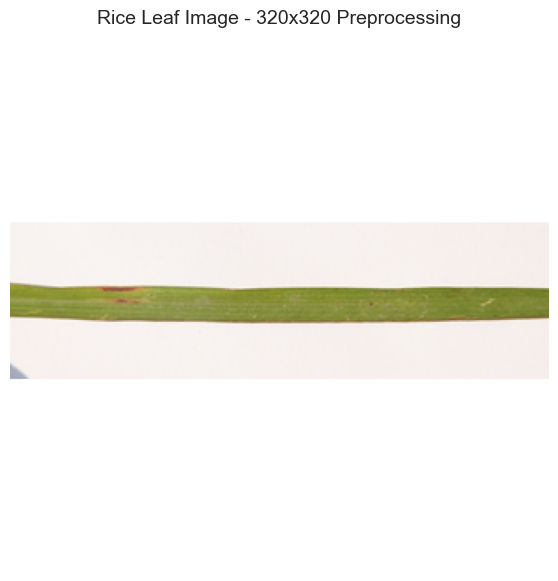

In [109]:
# Select one training image
sample_path = train_df.iloc[0]["Image_Path"]

# Apply 320x320 preprocessing
sample_image_320 = preprocess_image_320(sample_path)

print("Image shape:", sample_image_320.shape)
print("Data type:", sample_image_320.dtype)
print("Minimum pixel value:", sample_image_320.min())
print("Maximum pixel value:", sample_image_320.max())

# Display the processed image
plt.figure(figsize=(7, 7))
plt.imshow(sample_image_320)
plt.title("Rice Leaf Image - 320x320 Preprocessing")
plt.axis("off")
plt.show()

### 11.2 Creating TensorFlow Datasets for Higher-Resolution Images

The 320 × 320 preprocessed images are converted into TensorFlow datasets for model training and evaluation.

The same stratified training, validation, and test splits used in the 224 × 224 experiment are retained.

- Training dataset: 83 images
- Validation dataset: 18 images
- Test dataset: 18 images
- Batch size: 8
- Data augmentation: Disabled for this experiment

Reusing the same splits helps isolate the effect of changing image resolution.

In [110]:
# Create TensorFlow datasets for 320x320 images

BATCH_SIZE_320 = 8

def create_tf_dataset_320(data_frame, batch_size=8, shuffle=False):

    def data_generator():

        for _, row in data_frame.iterrows():

            image = preprocess_image_320(row["Image_Path"])
            label = int(row["Encoded_Label"])

            yield image, label

    dataset = tf.data.Dataset.from_generator(
        data_generator,
        output_signature=(
            tf.TensorSpec(
                shape=(320, 320, 3),
                dtype=tf.float32
            ),
            tf.TensorSpec(
                shape=(),
                dtype=tf.int32
            )
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(data_frame),
            seed=42
        )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create datasets using the existing splits

train_ds_320 = create_tf_dataset_320(
    train_df,
    batch_size=BATCH_SIZE_320,
    shuffle=True
)

val_ds_320 = create_tf_dataset_320(
    val_df,
    batch_size=BATCH_SIZE_320,
    shuffle=False
)

test_ds_320 = create_tf_dataset_320(
    test_df,
    batch_size=BATCH_SIZE_320,
    shuffle=False
)

print("320x320 datasets created successfully.")

320x320 datasets created successfully.


In [111]:
# Validate dataset batch counts

print("Training batches:", sum(1 for _ in train_ds_320))
print("Validation batches:", sum(1 for _ in val_ds_320))
print("Testing batches:", sum(1 for _ in test_ds_320))

# Inspect one training batch

sample_images, sample_labels = next(iter(train_ds_320))

print("\nImage batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Pixel minimum:", tf.reduce_min(sample_images).numpy())
print("Pixel maximum:", tf.reduce_max(sample_images).numpy())

Training batches: 11
Validation batches: 3
Testing batches: 3

Image batch shape: (8, 320, 320, 3)
Label batch shape: (8,)
Pixel minimum: 0.0
Pixel maximum: 1.0


### 11.3 Building the MobileNetV2 Model with 320 × 320 Input

MobileNetV2 is used as a pretrained feature extractor with ImageNet weights.

The model architecture consists of:

1. Input layer accepting 320 × 320 RGB images.
2. Pretrained MobileNetV2 convolutional base.
3. Global Average Pooling layer to reduce feature dimensions.
4. Dropout layer to reduce overfitting.
5. Dense output layer with three neurons and softmax activation for disease classification.

Initially, the pretrained convolutional base is frozen. Only the classification head is trained.

This approach uses transfer learning to leverage previously learned image features while adapting the final classification layer to the rice leaf disease dataset.

In [112]:
# Apply MobileNetV2 preprocessing to 320x320 datasets

def mobilenet_preprocessing_320(images, labels):

    images = tf.keras.applications.mobilenet_v2.preprocess_input(
        images * 255.0
    )

    return images, labels


mobilenet_train_ds_320 = train_ds_320.map(
    mobilenet_preprocessing_320
).prefetch(tf.data.AUTOTUNE)

mobilenet_val_ds_320 = val_ds_320.map(
    mobilenet_preprocessing_320
).prefetch(tf.data.AUTOTUNE)

mobilenet_test_ds_320 = test_ds_320.map(
    mobilenet_preprocessing_320
).prefetch(tf.data.AUTOTUNE)


# Validate preprocessing

sample_images_320, sample_labels_320 = next(
    iter(mobilenet_train_ds_320)
)

print("Image shape:", sample_images_320.shape)
print("Minimum pixel value:", tf.reduce_min(sample_images_320).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_images_320).numpy())

Image shape: (8, 320, 320, 3)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [113]:
# Load MobileNetV2 with ImageNet pretrained weights

mobilenet_base_320 = tf.keras.applications.MobileNetV2(
    input_shape=(320, 320, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained convolutional layers
mobilenet_base_320.trainable = False

print("MobileNetV2 base loaded successfully.")
print("Total layers:", len(mobilenet_base_320.layers))
print("Trainable:", mobilenet_base_320.trainable)

MobileNetV2 base loaded successfully.
Total layers: 154
Trainable: False


In [114]:
# Build the 320x320 MobileNetV2 model

mobilenet_model_320 = models.Sequential([

    layers.Input(shape=(320, 320, 3)),

    mobilenet_base_320,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )

], name="MobileNetV2_Rice_Disease_320")


# Compile model

mobilenet_model_320.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# Display model architecture

mobilenet_model_320.summary()

Model: "MobileNetV2_Rice_Disease_320"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 10, 10, 1280)        │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_4           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 11.4 Model Architecture Summary

The MobileNetV2 model was successfully configured to accept 320 × 320 RGB images.

The architecture contains 2,261,827 total parameters, of which 3,843 are trainable and 2,257,984 are non-trainable.

The pretrained MobileNetV2 base remains frozen, while the final classification head is trained for the three rice leaf disease categories.

The output layer uses softmax activation to generate class probabilities.

The model is ready for training using the higher-resolution dataset.

In [115]:
# Training callbacks for 320x320 MobileNetV2

checkpoint_path_320 = MODEL_DIR / "mobilenetv2_320_best.keras"

callbacks_320 = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path_320),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("Training callbacks configured successfully.")

Training callbacks configured successfully.


In [116]:
# Train 320x320 MobileNetV2

mobilenet_history_320 = mobilenet_model_320.fit(
    mobilenet_train_ds_320,
    validation_data=mobilenet_val_ds_320,
    epochs=30,
    callbacks=callbacks_320,
    verbose=1
)

Epoch 1/30
     11/Unknown 20s 665ms/step - accuracy: 0.4217 - loss: 1.0851
Epoch 1: val_loss improved from None to 1.05707, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_320_best.keras

Epoch 1: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_320_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.4217 - loss: 1.0851 - val_accuracy: 0.3889 - val_loss: 1.0571 - learning_rate: 1.0000e-04
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.4819 - loss: 1.0982
Epoch 2: val_loss improved from 1.05707 to 1.03411, saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_320_best.keras

Epoch 2: finished saving model to C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\mobilenetv2_320_best.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/st

### 11.5 Training Results – MobileNetV2 (320 × 320)

The 320 × 320 MobileNetV2 model was trained for 30 epochs using pretrained ImageNet weights with the convolutional base frozen.

**Final training metrics:**
- Training accuracy: 79.52%
- Training loss: 0.5657

**Final validation metrics:**
- Validation accuracy: 83.33%
- Validation loss: 0.7631

The best validation accuracy was 83.33%, while the best validation loss was 0.76305 at epoch 30.

**Initial comparison with the 224 × 224 model:**

The higher-resolution model achieved greater training accuracy, but validation accuracy remained unchanged at 83.33%. Its validation loss was slightly higher than that of the 224 × 224 model.

This suggests that increasing image resolution has not yet demonstrated a clear improvement in generalization.

Further evaluation using learning curves and the independent test dataset is required.

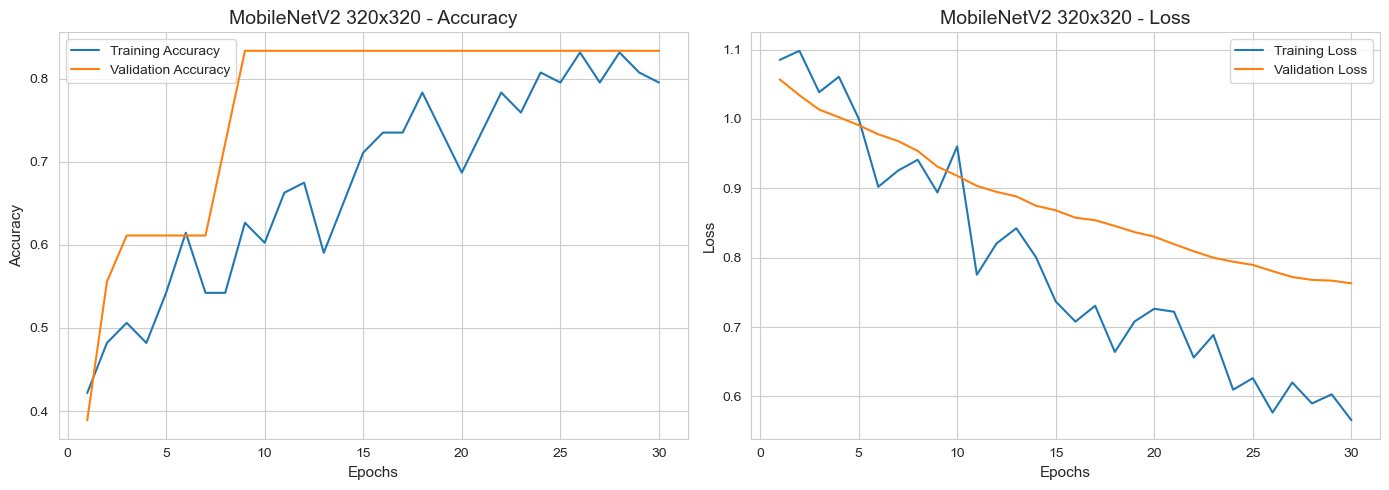

In [117]:
# Plot MobileNetV2 320x320 learning curves

mobile320_train_acc = mobilenet_history_320.history["accuracy"]
mobile320_val_acc = mobilenet_history_320.history["val_accuracy"]

mobile320_train_loss = mobilenet_history_320.history["loss"]
mobile320_val_loss = mobilenet_history_320.history["val_loss"]

epochs_range = range(1, len(mobile320_train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(
    epochs_range,
    mobile320_train_acc,
    label="Training Accuracy"
)

axes[0].plot(
    epochs_range,
    mobile320_val_acc,
    label="Validation Accuracy"
)

axes[0].set_title("MobileNetV2 320x320 - Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(
    epochs_range,
    mobile320_train_loss,
    label="Training Loss"
)

axes[1].plot(
    epochs_range,
    mobile320_val_loss,
    label="Validation Loss"
)

axes[1].set_title("MobileNetV2 320x320 - Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

# Save before displaying
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUTPUT_DIR / "mobilenetv2_320_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11.6 Learning Curve Analysis – MobileNetV2 (320 × 320)

The learning curves show that the higher-resolution MobileNetV2 model progressively learns image features over 30 epochs.

**Accuracy observations:**
- Training accuracy increased from approximately 42% to 79.52%.
- Validation accuracy reached 83.33% by epoch 9.
- Validation accuracy remained stable at 83.33% through the final epoch.

**Loss observations:**
- Training loss decreased from approximately 1.08 to 0.5657.
- Validation loss decreased from approximately 1.06 to 0.7631.
- Both loss curves demonstrate a downward trend.

**Interpretation:**

The model continues improving its training performance, while validation accuracy remains unchanged after epoch 9. The increasing separation between training and validation loss suggests a developing generalization gap.

However, validation loss continues to improve, indicating that the model's prediction quality may still be improving even though the number of correctly classified validation images remains unchanged.

**Conclusion:**

The 320 × 320 model achieved 83.33% validation accuracy, matching the 224 × 224 model. Higher resolution has not yet demonstrated a clear validation accuracy improvement. Independent test evaluation is required to determine whether it provides better generalization.

In [119]:
# Evaluate 320x320 MobileNetV2 on the test dataset

mobile320_test_loss, mobile320_test_accuracy = (
    mobilenet_model_320.evaluate(
        mobilenet_test_ds_320,
        verbose=1
    )
)

print(f"MobileNetV2 320 Test Loss: {mobile320_test_loss:.4f}")

print(
    f"MobileNetV2 320 Test Accuracy: "
    f"{mobile320_test_accuracy:.4f}"
)

print(
    f"MobileNetV2 320 Test Accuracy (%): "
    f"{mobile320_test_accuracy * 100:.2f}%"
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.8333 - loss: 0.5424
MobileNetV2 320 Test Loss: 0.5424
MobileNetV2 320 Test Accuracy: 0.8333
MobileNetV2 320 Test Accuracy (%): 83.33%


### 11.7 Test Evaluation – MobileNetV2 (320 × 320)

The 320 × 320 MobileNetV2 model was evaluated using the same test dataset used in the 224 × 224 experiment.

**Test performance:**
- Test accuracy: 83.33%
- Test loss: 0.5424
- Correct predictions: 15 out of 18 images.

**Comparison with the 224 × 224 model:**

The 224 × 224 model achieved 66.67% test accuracy, whereas the 320 × 320 model achieved 83.33%.

The higher-resolution model correctly classified three additional test images. Test loss also decreased from 0.6768 to 0.5424.

**Interpretation:**

These results suggest that higher-resolution image input may help preserve disease-related visual details and improve classification performance.

However, the validation accuracy remained unchanged at 83.33%. The test dataset is also small, and repeated evaluation on the same test set introduces model-selection bias.

**Conclusion:**

MobileNetV2 with 320 × 320 input is the stronger candidate based on the observed test results. Further class-wise evaluation is required, particularly to determine whether Leaf smut recognition has improved.

3/3 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step


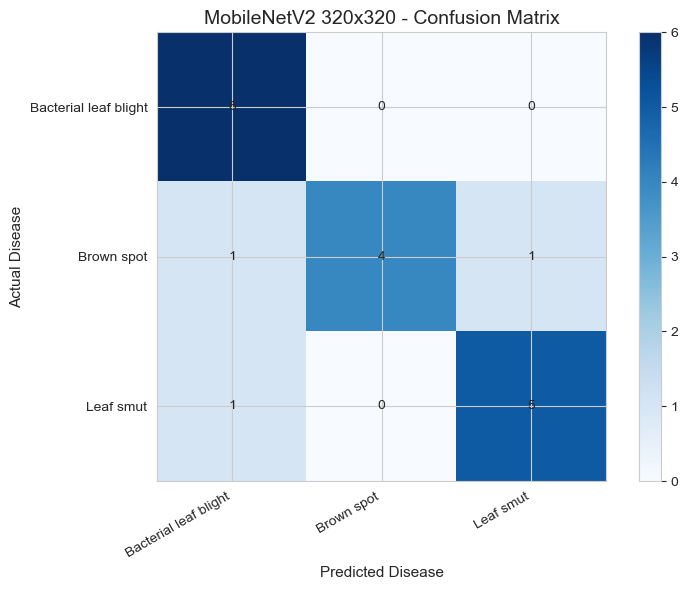

MobileNetV2 320x320 Classification Report
                       precision    recall  f1-score   support

Bacterial leaf blight       0.75      1.00      0.86         6
           Brown spot       1.00      0.67      0.80         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.83        18
            macro avg       0.86      0.83      0.83        18
         weighted avg       0.86      0.83      0.83        18



In [120]:
# Generate predictions using MobileNetV2 320x320

y_prob_320 = mobilenet_model_320.predict(
    mobilenet_test_ds_320,
    verbose=1
)

y_pred_320 = np.argmax(y_prob_320, axis=1)

# Actual labels from the same test dataset
y_true_320 = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_test_ds_320
])

# Confusion matrix
cm_320 = confusion_matrix(
    y_true_320,
    y_pred_320,
    labels=np.arange(NUM_CLASSES)
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

plt.imshow(cm_320, interpolation="nearest", cmap="Blues")
plt.title("MobileNetV2 320x320 - Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(NUM_CLASSES)

plt.xticks(tick_marks, class_names, rotation=30, ha="right")
plt.yticks(tick_marks, class_names)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j, i, cm_320[i, j],
            ha="center",
            va="center"
        )

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.tight_layout()
plt.show()

# Classification report
print("MobileNetV2 320x320 Classification Report")

print(
    classification_report(
        y_true_320,
        y_pred_320,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )
)

### 11.8 Confusion Matrix and Classification Report – MobileNetV2 (320 × 320)

The 320 × 320 MobileNetV2 model achieved 83.33% test accuracy, correctly classifying 15 out of 18 test images.

**Class-wise observations:**

1. Bacterial leaf blight achieved 100% recall, with all six images correctly classified.
2. Brown spot achieved 66.67% recall, with four out of six images correctly classified.
3. Leaf smut achieved 83.33% recall, with five out of six images correctly classified.

**Classification report:**

- Accuracy: 83.33%
- Macro precision: 0.86
- Macro recall: 0.83
- Macro F1-score: 0.83
- Weighted F1-score: 0.83

**Comparison with the 224 × 224 model:**

Leaf smut recall improved significantly from 16.67% to 83.33%. Brown spot recall decreased from 83.33% to 66.67%, while Bacterial leaf blight recall remained at 100%.

The macro F1-score improved from 0.62 to 0.83, indicating better overall balance across disease categories.

**Conclusion:**

The 320 × 320 MobileNetV2 model is the stronger candidate based on the observed test results. Higher-resolution input appears to have helped the model distinguish Leaf smut more effectively, although Brown spot performance declined.

The test dataset contains only 18 images, so these results should be interpreted cautiously. Further validation on a larger independent dataset is recommended before production deployment.

In [121]:
# Identify misclassified images from 320x320 model

misclassified_320 = np.where(y_true_320 != y_pred_320)[0]

print("Total misclassified images:", len(misclassified_320))

for idx in misclassified_320:

    print("\nActual:", class_names[y_true_320[idx]])
    print("Predicted:", class_names[y_pred_320[idx]])

    print("Prediction probabilities:")

    for class_index, class_name in enumerate(class_names):
        print(
            f"{class_name}: "
            f"{y_prob_320[idx][class_index] * 100:.2f}%"
        )

Total misclassified images: 3

Actual: Leaf smut
Predicted: Bacterial leaf blight
Prediction probabilities:
Bacterial leaf blight: 50.77%
Brown spot: 15.32%
Leaf smut: 33.91%

Actual: Brown spot
Predicted: Leaf smut
Prediction probabilities:
Bacterial leaf blight: 26.31%
Brown spot: 35.41%
Leaf smut: 38.28%

Actual: Brown spot
Predicted: Bacterial leaf blight
Prediction probabilities:
Bacterial leaf blight: 43.51%
Brown spot: 40.60%
Leaf smut: 15.89%


### 11.9 Prediction Confidence Analysis – MobileNetV2 (320 × 320)

The prediction probabilities of the three misclassified test images were examined to understand model uncertainty.

**Observations:**

1. One Leaf smut image was incorrectly classified as Bacterial leaf blight with 50.77% confidence.
2. One Brown spot image was classified as Leaf smut with 38.28% confidence.
3. Another Brown spot image was classified as Bacterial leaf blight with 43.51% confidence.

**Interpretation:**

The predicted probabilities for these images are relatively close across multiple classes, indicating uncertainty in disease classification.

The model has improved Leaf smut recognition considerably compared with the 224 × 224 experiment, but Brown spot remains a challenging category.

**Conclusion:**

The 320 × 320 model demonstrates improved classification performance, but the remaining errors indicate that additional data and further investigation of disease-specific visual features may be beneficial.

### 12. Comparative Model Evaluation

Multiple deep-learning approaches were investigated for rice leaf disease classification.

The experiments included a custom baseline CNN, an augmented CNN, and MobileNetV2 transfer-learning models at two input resolutions.

The comparison considers training performance, validation performance, test performance, and class-wise evaluation metrics.

The higher-resolution MobileNetV2 model achieved the strongest observed test performance, with 83.33% accuracy and a macro F1-score of 0.83.

Preprocessing differences between experiments are acknowledged as a limitation when interpreting the comparison.

In [124]:
# Create model comparison dataframe

model_comparison = pd.DataFrame({

    "Model": [
        "Baseline CNN",
        "Augmented CNN",
        "MobileNetV2 224x224",
        "MobileNetV2 320x320"
    ],

    "Training Accuracy (%)": [
        63.86,
        62.65,
        72.29,
        79.52
    ],

    "Validation Accuracy (%)": [
        44.44,
        44.44,
        83.33,
        83.33
    ],

    "Test Accuracy (%)": [
        np.nan,
        np.nan,
        66.67,
        83.33
    ],

    "Test Loss": [
        np.nan,
        np.nan,
        0.6768,
        0.5424
    ]
})

model_comparison

,Model,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Test Loss
0,Baseline CNN,63.86,44.44,NaN,NaN
1,Augmented CNN,62.65,44.44,NaN,NaN
2,MobileNetV2 224x224,72.29,83.33,66.67,0.6768
3,MobileNetV2 320x320,79.52,83.33,83.33,0.5424


In [125]:
model_comparison = pd.DataFrame({

    "Model": [
        "Baseline CNN",
        "Augmented CNN",
        "MobileNetV2 (224x224)",
        "MobileNetV2 (320x320)"
    ],

    "Training Accuracy (%)": [
        63.86, 62.65, 72.29, 79.52
    ],

    "Validation Accuracy (%)": [
        44.44, 44.44, 83.33, 83.33
    ],

    "Test Accuracy (%)": [
        np.nan, np.nan, 66.67, 83.33
    ],

    "Test Loss": [
        np.nan, np.nan, 0.6768, 0.5424
    ],

    "Macro F1 Score": [
        np.nan, np.nan, 0.62, 0.83
    ]
})

model_comparison

,Model,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Test Loss,Macro F1 Score
0,Baseline CNN,63.86,44.44,NaN,NaN,NaN
1,Augmented CNN,62.65,44.44,NaN,NaN,NaN
2,MobileNetV2 (224x224),72.29,83.33,66.67,0.6768,0.62
3,MobileNetV2 (320x320),79.52,83.33,83.33,0.5424,0.83


### 12.1 Comparative Model Analysis

Four deep-learning configurations were investigated for rice leaf disease classification.

**Key findings:**

1. The baseline CNN achieved 44.44% validation accuracy.
2. The augmented CNN also achieved 44.44% validation accuracy, showing no observed validation accuracy improvement over the baseline.
3. MobileNetV2 with 224 × 224 input achieved 83.33% validation accuracy and 66.67% test accuracy.
4. MobileNetV2 with 320 × 320 input achieved 83.33% validation accuracy and 83.33% test accuracy.

The 320 × 320 MobileNetV2 model achieved the strongest observed test performance, with a macro F1-score of 0.83.

**Model selection:**

Based on the available experimental results, MobileNetV2 with 320 × 320 input is selected as the leading candidate for further evaluation.

The comparison has limitations because preprocessing differed between some experiments, and the same test set was used for multiple model evaluations. Therefore, the observed test results should be treated as exploratory rather than definitive evidence of generalization.

## 13. Model Interpretability Using Grad-CAM

### 13.1 Introduction

Grad-CAM (Gradient-weighted Class Activation Mapping) is an explainable AI technique used to visualize the image regions that contribute to a deep-learning model's predictions.

For this project, Grad-CAM is applied to the MobileNetV2 320 × 320 model to understand which regions of rice leaf images influence disease classification.

### Objectives

- Identify image regions that influence model predictions.
- Investigate whether the model focuses on disease-affected areas.
- Examine possible reliance on irrelevant background features.
- Improve the interpretability and transparency of the classification model.

Grad-CAM visualizations provide qualitative explanations and do not independently prove that the model has learned the correct biological disease features.

In [127]:
# Identify the last convolutional layer in MobileNetV2

last_conv_layer = mobilenet_base_320.get_layer("out_relu")

print("Last convolutional layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

Last convolutional layer: out_relu
Output shape: (None, 10, 10, 1280)


### 13.4 Grad-CAM Heatmap Generation

A Grad-CAM heatmap is generated by calculating gradients of the predicted class score with respect to the output of the last convolutional layer.

The gradients are averaged across spatial dimensions to obtain importance weights for the feature channels. These weights are combined with the feature maps to generate a heatmap.

The heatmap is normalized and resized to match the original image dimensions so that important image regions can be visualized.

In [137]:
def generate_gradcam(
    image,
    model,
    base_model,
    last_conv_layer_name="out_relu",
    pred_index=None
):
    # 1. Extract the selected convolutional layer output
    base_grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=base_model.get_layer(last_conv_layer_name).output
    )

    # 2. Reuse the trained classification head
    pooling_layer = model.layers[1]
    dropout_layer = model.layers[2]
    classifier_layer = model.layers[3]

    # 3. Build a model that returns feature maps and predictions
    inputs = tf.keras.Input(shape=(320, 320, 3))

    conv_features = base_grad_model(inputs, training=False)

    x = pooling_layer(conv_features)
    x = dropout_layer(x, training=False)
    predictions = classifier_layer(x)

    grad_model = tf.keras.Model(
        inputs=inputs,
        outputs=[conv_features, predictions]
    )

    # 4. Calculate gradients
    with tf.GradientTape() as tape:

        input_image = tf.expand_dims(image, axis=0)

        conv_outputs, predictions = grad_model(
            input_image,
            training=False
        )

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    grads = tape.gradient(class_score, conv_outputs)

    # 5. Calculate channel importance
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    # 6. Generate heatmap
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [138]:
heatmap = generate_gradcam(
    image=sample_image,
    model=mobilenet_model_320,
    base_model=mobilenet_base_320
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap shape: (10, 10)
Heatmap minimum: 0.0
Heatmap maximum: 0.9999942


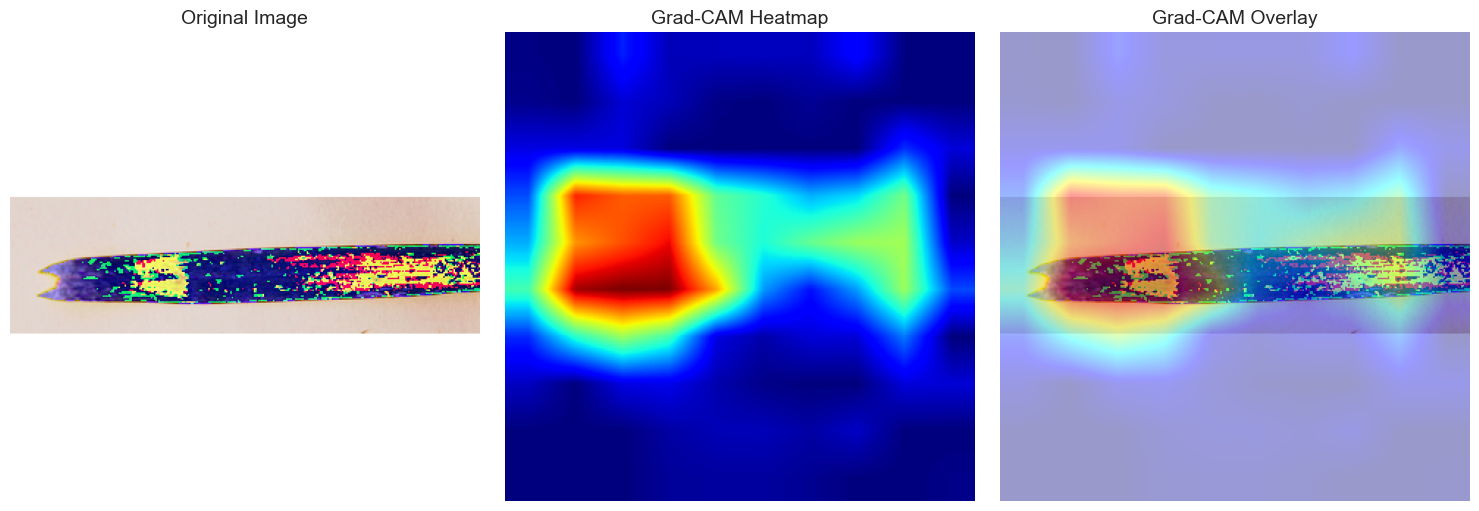

In [140]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Convert the input image to uint8
original_image = (
    sample_image.numpy() * 255
).astype(np.uint8)

# Resize heatmap to original image dimensions
heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

# Convert heatmap to colour
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_colored,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original image
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

### Grad-CAM Visualization – Observations and Interpretation

Grad-CAM was applied to the trained MobileNetV2 model with an input resolution of 320 × 320 to understand the spatial regions influencing its predictions.

**Observations:**

- The strongest activation is concentrated around the left-to-middle region of the leaf.
- Several other regions along the leaf also contribute to the prediction.
- Some activation extends into the background surrounding the leaf.
- The heatmap suggests that the model is using features from the leaf region, but it does not establish that these features are exclusively disease-related.

**Conclusion:**

The Grad-CAM visualization provides an initial explanation of the model's prediction. However, further inspection across correctly classified and misclassified samples from all three disease categories is required to assess whether the model consistently focuses on relevant leaf regions.

Grad-CAM is an interpretability technique and does not independently establish biological correctness or model reliability.

In [145]:
import numpy as np
import pandas as pd
import tensorflow as tf

gradcam_samples = []

for _, row in test_df.iterrows():

    # Load image using the existing 320x320 preprocessing
    image_01 = preprocess_image_320(row["Image_Path"])

    # Apply MobileNetV2 preprocessing: [0,1] to [-1,1]
    image_input = tf.keras.applications.mobilenet_v2.preprocess_input(
        np.expand_dims(image_01 * 255.0, axis=0)
    )

    # Predict
    probabilities = mobilenet_model_320.predict(
        image_input,
        verbose=0
    )[0]

    predicted_label = int(np.argmax(probabilities))
    actual_label = int(
    label_encoder.transform([row["Disease_Class"]])[0]
)

    gradcam_samples.append({
        "Image_Path": row["Image_Path"],
        "Image_Name": row["Image_Name"],
        "Actual_Class": class_names[actual_label],
        "Predicted_Class": class_names[predicted_label],
        "Correct": actual_label == predicted_label,
        "Confidence": round(float(np.max(probabilities)) * 100, 2),
        "Image_Array": image_01
    })

gradcam_results = pd.DataFrame(gradcam_samples)

display(
    gradcam_results[
        ["Image_Name", "Actual_Class", "Predicted_Class",
         "Correct", "Confidence"]
    ].style.hide(axis="index")
)

Image_Name,Actual_Class,Predicted_Class,Correct,Confidence
DSC_0321.JPG,Leaf smut,Leaf smut,True,71.400000
DSC_0119.jpg,Brown spot,Brown spot,True,69.500000
DSC_0110.jpg,Brown spot,Brown spot,True,67.020000
DSC_0105.jpg,Brown spot,Brown spot,True,62.670000
DSC_0389.JPG,Bacterial leaf blight,Bacterial leaf blight,True,65.350000
DSC_0327.JPG,Leaf smut,Leaf smut,True,46.020000
DSC_0386.JPG,Bacterial leaf blight,Bacterial leaf blight,True,76.800000
DSC_0315.jpg,Leaf smut,Leaf smut,True,53.170000
DSC_0382.JPG,Bacterial leaf blight,Bacterial leaf blight,True,80.320000
DSC_0336.jpg,Leaf smut,Bacterial leaf blight,False,50.770000


In [146]:
def generate_gradcam(
    image,
    model,
    base_model,
    last_conv_layer_name="out_relu",
    pred_index=None
):
    # Extract convolutional feature maps
    base_grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=base_model.get_layer(last_conv_layer_name).output
    )

    # Reuse trained classification head
    pooling_layer = model.layers[1]
    dropout_layer = model.layers[2]
    classifier_layer = model.layers[3]

    inputs = tf.keras.Input(shape=(320, 320, 3))

    conv_features = base_grad_model(inputs, training=False)

    x = pooling_layer(conv_features)
    x = dropout_layer(x, training=False)
    predictions = classifier_layer(x)

    grad_model = tf.keras.Model(
        inputs=inputs,
        outputs=[conv_features, predictions]
    )

    # Apply the SAME preprocessing used during model training
    input_image = tf.convert_to_tensor(image, dtype=tf.float32)
    input_image = tf.expand_dims(input_image * 255.0, axis=0)

    input_image = tf.keras.applications.mobilenet_v2.preprocess_input(
        input_image
    )

    # Calculate gradients
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            input_image,
            training=False
        )

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    grads = tape.gradient(class_score, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [147]:
selected_images = {
    "Bacterial leaf blight": "DSC_0389.JPG",
    "Brown spot": "DSC_0119.jpg",
    "Leaf smut": "DSC_0321.JPG",
    "Misclassified": "DSC_0301.JPG"
}

selected_gradcam_df = gradcam_results[
    gradcam_results["Image_Name"].isin(
        selected_images.values()
    )
].copy()

display(
    selected_gradcam_df[
        ["Image_Name", "Actual_Class", "Predicted_Class",
         "Correct", "Confidence"]
    ].style.hide(axis="index")
)

Image_Name,Actual_Class,Predicted_Class,Correct,Confidence
DSC_0321.JPG,Leaf smut,Leaf smut,True,71.400000
DSC_0119.jpg,Brown spot,Brown spot,True,69.500000
DSC_0389.JPG,Bacterial leaf blight,Bacterial leaf blight,True,65.350000
DSC_0301.JPG,Brown spot,Leaf smut,False,38.280000


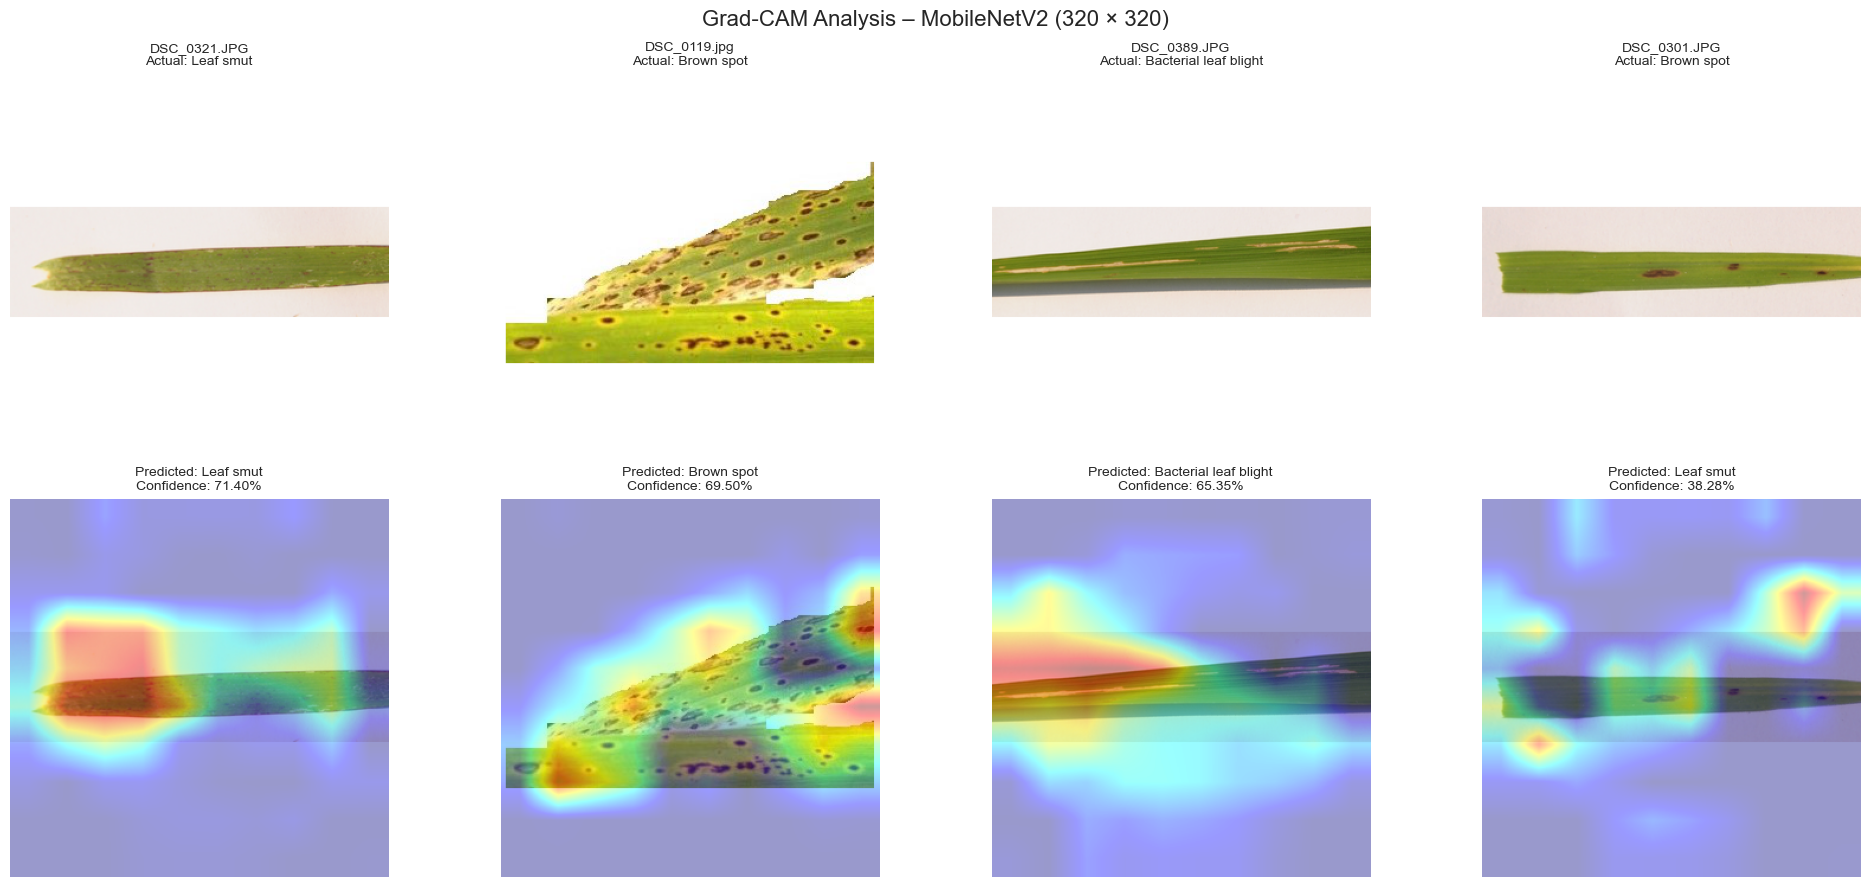

In [148]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for col, (_, row) in enumerate(selected_gradcam_df.iterrows()):

    # Retrieve image
    image = row["Image_Array"]

    # Get predicted class index
    predicted_index = int(
        label_encoder.transform([row["Predicted_Class"]])[0]
    )

    # Generate Grad-CAM for predicted class
    heatmap = generate_gradcam(
        image=image,
        model=mobilenet_model_320,
        base_model=mobilenet_base_320,
        pred_index=predicted_index
    )

    # Convert original image to uint8
    original_image = (image * 255).astype(np.uint8)

    # Resize heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (original_image.shape[1], original_image.shape[0])
    )

    # Apply colour map
    heatmap_colored = np.uint8(255 * heatmap_resized)

    heatmap_colored = cv2.applyColorMap(
        heatmap_colored,
        cv2.COLORMAP_JET
    )

    heatmap_colored = cv2.cvtColor(
        heatmap_colored,
        cv2.COLOR_BGR2RGB
    )

    # Overlay
    overlay = cv2.addWeighted(
        original_image,
        0.6,
        heatmap_colored,
        0.4,
        0
    )

    # Display original image
    axes[0, col].imshow(original_image)
    axes[0, col].set_title(
        f'{row["Image_Name"]}\nActual: {row["Actual_Class"]}',
        fontsize=10
    )
    axes[0, col].axis("off")

    # Display Grad-CAM overlay
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(
        f'Predicted: {row["Predicted_Class"]}\n'
        f'Confidence: {row["Confidence"]:.2f}%',
        fontsize=10
    )
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Original Images", fontsize=12)
axes[1, 0].set_ylabel("Grad-CAM Overlays", fontsize=12)

plt.suptitle(
    "Grad-CAM Analysis – MobileNetV2 (320 × 320)",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Grad-CAM Analysis – Comparative Observations

Grad-CAM was performed on four representative test images using the trained MobileNetV2 model with an input resolution of 320 × 320.

**Key observations:**

1. **Bacterial leaf blight:** The model correctly classified the image, although its strongest activation was not consistently aligned with the visible disease symptoms.
2. **Brown spot:** The correctly classified image showed activation overlapping with some visible brown lesions, suggesting that lesion-related visual features may contribute to the prediction.
3. **Leaf smut:** The model correctly classified the image, with activation concentrated around portions of the leaf. However, some background activation was also observed.
4. **Misclassified Brown spot:** The model predicted Leaf smut instead of Brown spot, with a confidence of 38.28%. The activation was distributed across multiple regions, indicating an uncertain prediction.

**Overall conclusion:**

The Grad-CAM analysis provides an initial explanation of the MobileNetV2 model's predictions. Although some attention overlaps with visible leaf symptoms, background activation is also present. Therefore, the model may be using a combination of leaf characteristics and other visual patterns.

Further investigation using a larger and more diverse dataset, additional correctly classified and misclassified samples, and quantitative interpretability techniques would be useful to assess model reliability.

These observations are qualitative and should not be interpreted as proof of disease-specific feature learning.

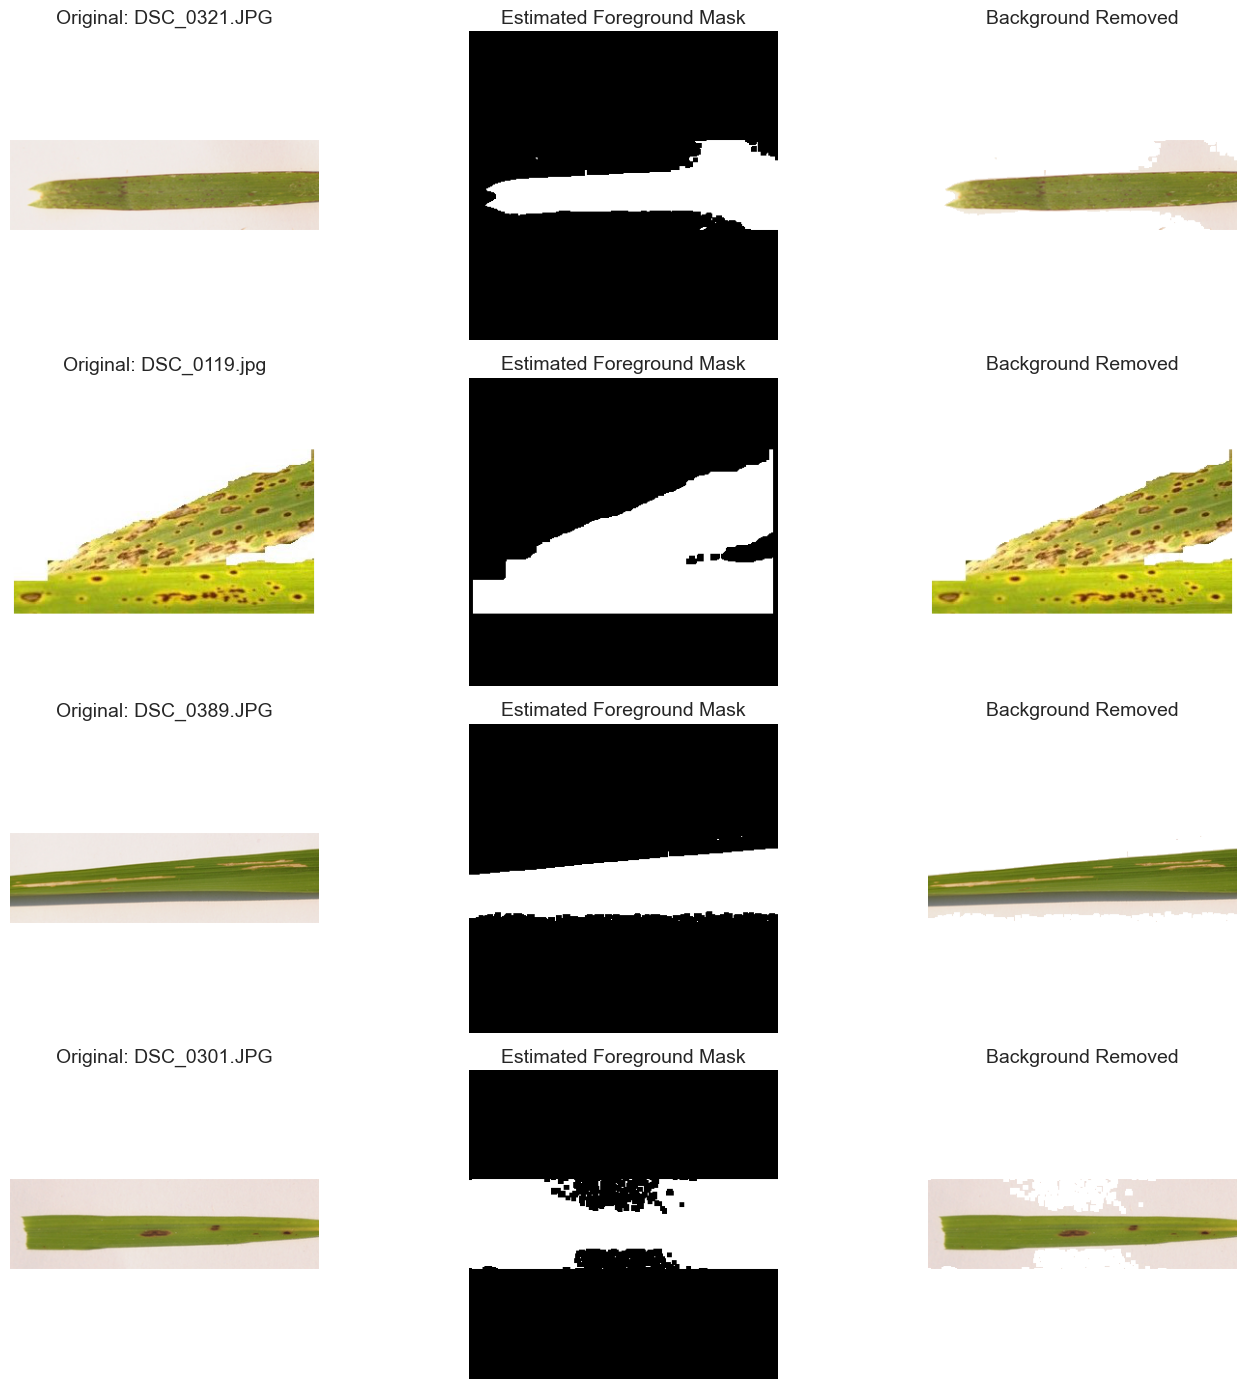

In [149]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def create_leaf_mask(image):
    """
    Create an approximate leaf foreground mask
    using HSV colour saturation.
    """

    # Convert image to uint8
    image_uint8 = (image * 255).astype(np.uint8)

    # Convert RGB to HSV
    hsv = cv2.cvtColor(
        image_uint8,
        cv2.COLOR_RGB2HSV
    )

    # Extract saturation channel
    saturation = hsv[:, :, 1]

    # Identify coloured regions
    mask = np.where(
        saturation > 20,
        255,
        0
    ).astype(np.uint8)

    # Remove small isolated regions
    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    return mask


# Display results for the four selected images
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for row_index, (_, row) in enumerate(
    selected_gradcam_df.iterrows()
):

    image = row["Image_Array"]

    # Generate mask
    leaf_mask = create_leaf_mask(image)

    # Retain leaf and replace background with white
    leaf_only = image.copy()

    leaf_only[leaf_mask == 0] = 1.0

    # Display original
    axes[row_index, 0].imshow(image)
    axes[row_index, 0].set_title(
        f'Original: {row["Image_Name"]}'
    )

    # Display mask
    axes[row_index, 1].imshow(
        leaf_mask,
        cmap="gray"
    )
    axes[row_index, 1].set_title("Estimated Foreground Mask")

    # Display leaf-only image
    axes[row_index, 2].imshow(leaf_only)
    axes[row_index, 2].set_title("Background Removed")

    for ax in axes[row_index]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [150]:
def create_leaf_mask_grabcut(image):

    # Convert image to uint8
    image_uint8 = (image * 255).astype(np.uint8)

    # Initialise mask
    mask = np.zeros(
        image_uint8.shape[:2],
        np.uint8
    )

    height, width = image_uint8.shape[:2]

    # Define rectangle around the leaf
    rect = (
        5,
        int(height * 0.25),
        width - 10,
        int(height * 0.50)
    )

    # Create background and foreground models
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    # Apply GrabCut
    cv2.grabCut(
        image_uint8,
        mask,
        rect,
        bgd_model,
        fgd_model,
        5,
        cv2.GC_INIT_WITH_RECT
    )

    # Extract probable and definite foreground
    leaf_mask = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    return leaf_mask

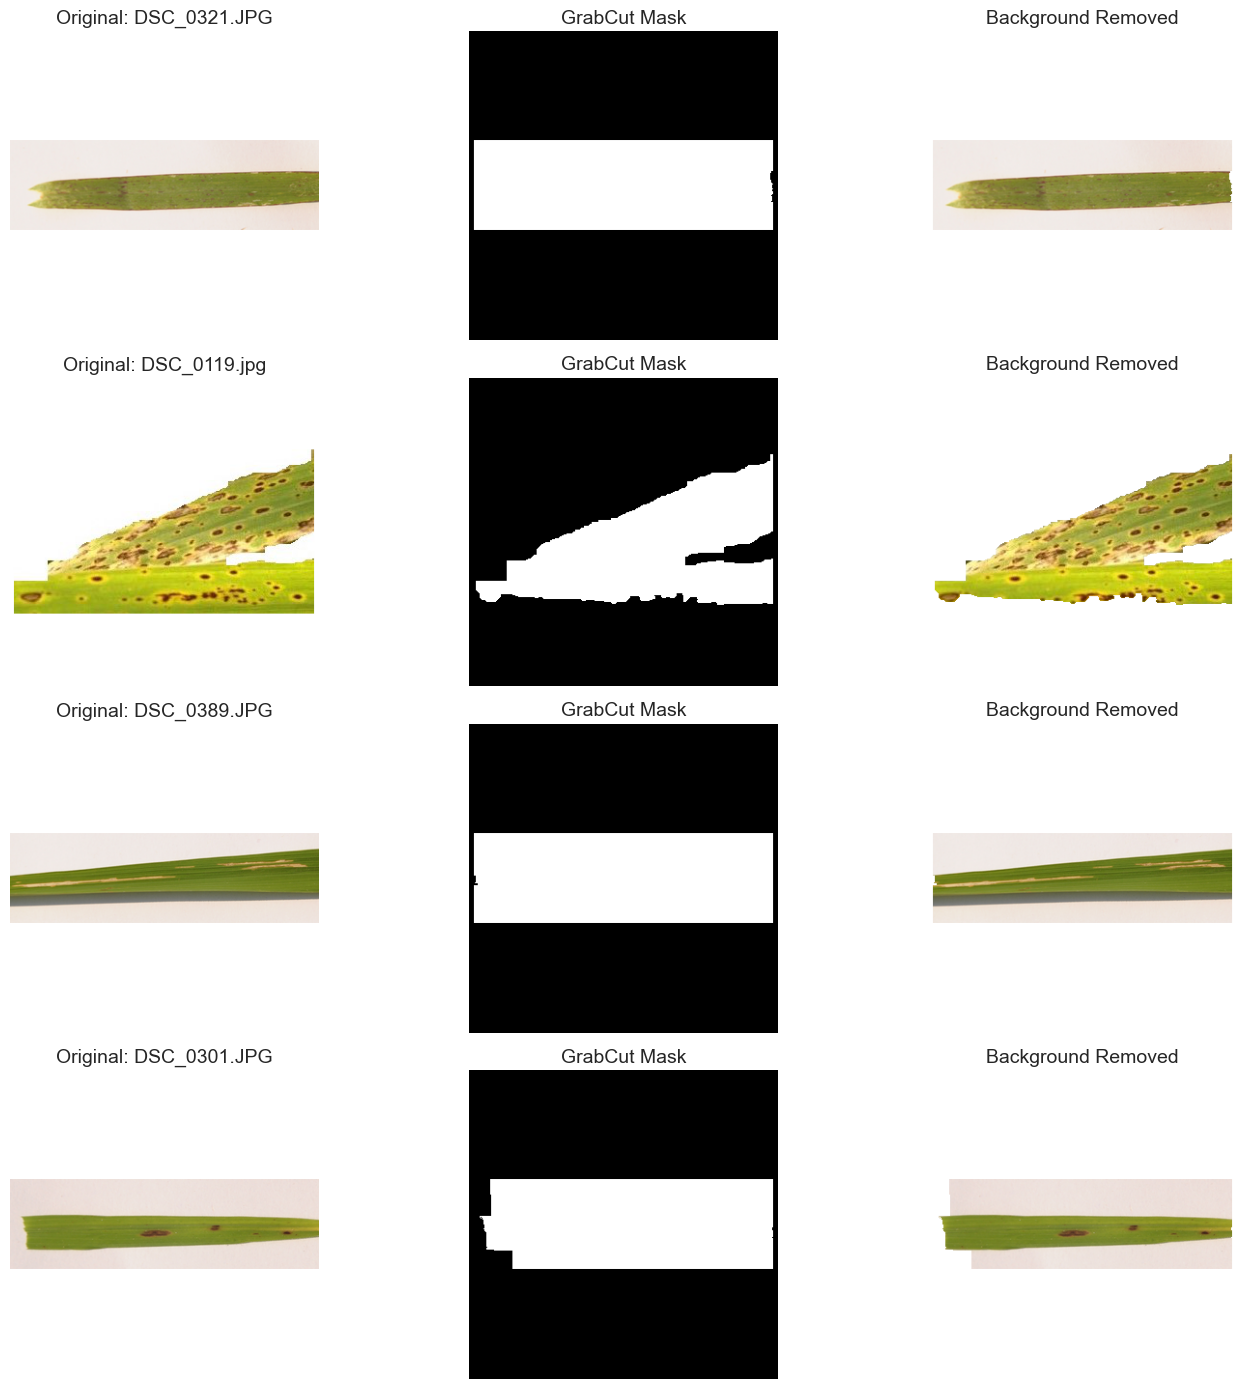

In [151]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for row_index, (_, row) in enumerate(
    selected_gradcam_df.iterrows()
):

    image = row["Image_Array"]

    # Generate improved mask
    leaf_mask = create_leaf_mask_grabcut(image)

    # Remove background
    leaf_only = image.copy()
    leaf_only[leaf_mask == 0] = 1.0

    axes[row_index, 0].imshow(image)
    axes[row_index, 0].set_title(
        f'Original: {row["Image_Name"]}'
    )

    axes[row_index, 1].imshow(
        leaf_mask,
        cmap="gray"
    )
    axes[row_index, 1].set_title("GrabCut Mask")

    axes[row_index, 2].imshow(leaf_only)
    axes[row_index, 2].set_title("Background Removed")

    for ax in axes[row_index]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Background Segmentation Experiment – Observations

Two segmentation approaches were investigated:

1. HSV saturation thresholding.
2. OpenCV GrabCut segmentation.

The HSV method produced inconsistent masks because leaf regions and backgrounds have varying saturation levels.

GrabCut improved the foreground extraction for some images but produced rectangular masks for others, particularly Bacterial leaf blight.

**Conclusion:**

Neither segmentation method produced sufficiently consistent leaf masks across all representative images. Therefore, these masks were not considered reliable enough for quantitative model evaluation.

A controlled background perturbation experiment will be considered as an alternative approach to investigate potential background and padding sensitivity.

In [153]:
import numpy as np
import matplotlib.pyplot as plt

def create_padding_variations(image):

    image = image.copy()

    # Identify nearly pure-white pixels
    padding_mask = np.all(image >= 0.999, axis=-1)

    # Original image
    original = image.copy()

    # Gray padding
    gray_image = image.copy()
    gray_image[padding_mask] = [0.5, 0.5, 0.5]

    # Black padding
    black_image = image.copy()
    black_image[padding_mask] = [0.0, 0.0, 0.0]

    return original, gray_image, black_image, padding_mask

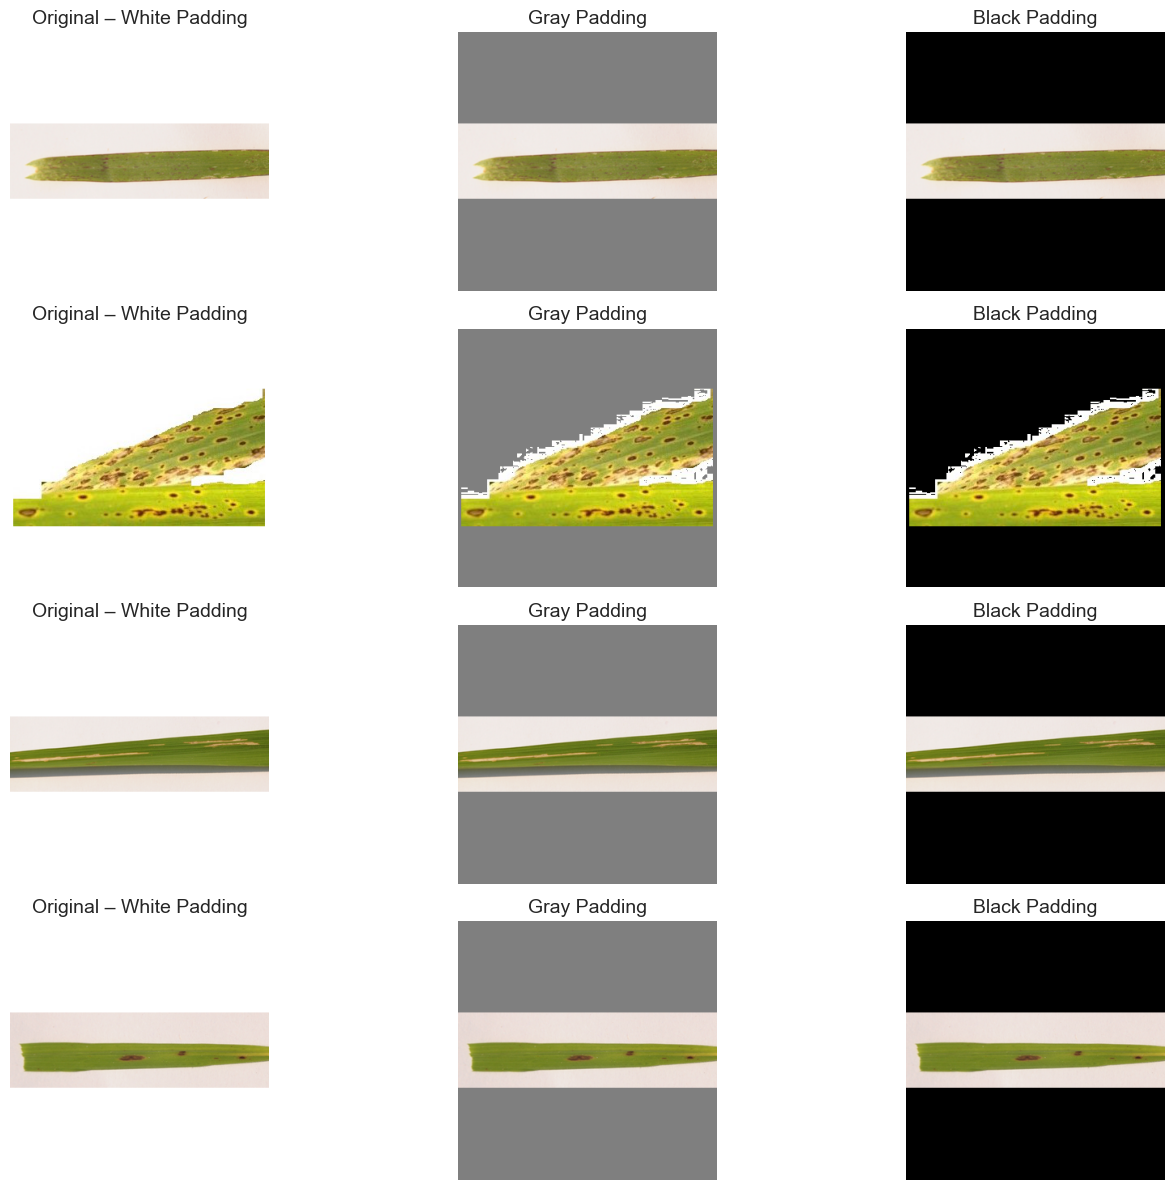

In [154]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for row_index, (_, row) in enumerate(
    selected_gradcam_df.iterrows()
):

    image = row["Image_Array"]

    original, gray, black, mask = create_padding_variations(image)

    axes[row_index, 0].imshow(original)
    axes[row_index, 0].set_title("Original – White Padding")

    axes[row_index, 1].imshow(gray)
    axes[row_index, 1].set_title("Gray Padding")

    axes[row_index, 2].imshow(black)
    axes[row_index, 2].set_title("Black Padding")

    for ax in axes[row_index]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [155]:
padding_results = []

for _, row in selected_gradcam_df.iterrows():

    image = row["Image_Array"]

    original, gray, black, mask = create_padding_variations(image)

    variations = {
        "White padding": original,
        "Gray padding": gray,
        "Black padding": black
    }

    original_prediction = None

    for variation_name, variation_image in variations.items():

        # Apply the same preprocessing used during training
        model_input = tf.keras.applications.mobilenet_v2.preprocess_input(
            np.expand_dims(variation_image * 255.0, axis=0)
        )

        # Predict
        probabilities = mobilenet_model_320.predict(
            model_input,
            verbose=0
        )[0]

        predicted_index = int(np.argmax(probabilities))
        predicted_class = class_names[predicted_index]
        confidence = float(np.max(probabilities)) * 100

        if variation_name == "White padding":
            original_prediction = predicted_class

        padding_results.append({
            "Image_Name": row["Image_Name"],
            "Actual_Class": row["Actual_Class"],
            "Padding_Type": variation_name,
            "Predicted_Class": predicted_class,
            "Confidence": round(confidence, 2),
            "Prediction_Changed": predicted_class != original_prediction
        })

padding_results_df = pd.DataFrame(padding_results)

display(
    padding_results_df.style.hide(axis="index")
)

Image_Name,Actual_Class,Padding_Type,Predicted_Class,Confidence,Prediction_Changed
DSC_0321.JPG,Leaf smut,White padding,Leaf smut,71.400000,False
DSC_0321.JPG,Leaf smut,Gray padding,Leaf smut,74.150000,False
DSC_0321.JPG,Leaf smut,Black padding,Leaf smut,59.220000,False
DSC_0119.jpg,Brown spot,White padding,Brown spot,69.500000,False
DSC_0119.jpg,Brown spot,Gray padding,Brown spot,71.330000,False
DSC_0119.jpg,Brown spot,Black padding,Brown spot,73.490000,False
DSC_0389.JPG,Bacterial leaf blight,White padding,Bacterial leaf blight,65.350000,False
DSC_0389.JPG,Bacterial leaf blight,Gray padding,Bacterial leaf blight,47.470000,False
DSC_0389.JPG,Bacterial leaf blight,Black padding,Bacterial leaf blight,34.120000,False
DSC_0301.JPG,Brown spot,White padding,Leaf smut,38.280000,False


### Padding Sensitivity Analysis – Results and Interpretation

A controlled input sensitivity experiment was conducted using three image variations:

1. Original images with white padding.
2. Images with near-white pixels replaced by gray.
3. Images with near-white pixels replaced by black.

The trained MobileNetV2 model was evaluated on all three variations for four representative test images.

**Key findings:**

- The predicted classes remained unchanged for three images, although prediction confidence varied.
- The Bacterial leaf blight example showed a confidence reduction from 65.35% with white padding to 34.12% with black padding.
- The misclassified Brown spot image changed its predicted class from Leaf smut to Brown spot after modifying near-white pixels.
- The correctly classified Leaf smut and Brown spot examples retained their predicted classes across all variations.

**Conclusion:**

The experiment indicates that the model's predictions and confidence can be sensitive to changes in near-white image regions. This raises a potential concern regarding background and preprocessing sensitivity.

However, since the modified pixels may include naturally white image regions, and only four images were evaluated, this experiment does not independently establish background bias.

Further testing across the complete test dataset is required to determine whether this sensitivity is consistent.


In [157]:
padding_results_all = []

for _, row in test_df.iterrows():

    # Load the original 320x320 image
    image = preprocess_image_320(row["Image_Path"])

    # Convert actual class into numeric label
    actual_label = int(
        label_encoder.transform([row["Disease_Class"]])[0]
    )

    # Generate padding variations
    original, gray, black, mask = create_padding_variations(image)

    variations = {
        "White": original,
        "Gray": gray,
        "Black": black
    }

    white_prediction = None

    for padding_type, variation_image in variations.items():

        # Apply MobileNetV2 preprocessing
        model_input = tf.keras.applications.mobilenet_v2.preprocess_input(
            np.expand_dims(variation_image * 255.0, axis=0)
        )

        # Generate prediction
        probabilities = mobilenet_model_320.predict(
            model_input,
            verbose=0
        )[0]

        predicted_label = int(np.argmax(probabilities))

        predicted_class = class_names[predicted_label]

        confidence = float(np.max(probabilities)) * 100

        # Store original white-padding prediction
        if padding_type == "White":
            white_prediction = predicted_label

        padding_results_all.append({
            "Image_Name": row["Image_Name"],
            "Actual_Class": row["Disease_Class"],
            "Padding_Type": padding_type,
            "Predicted_Class": predicted_class,
            "Confidence": round(confidence, 2),
            "Correct": predicted_label == actual_label,
            "Prediction_Changed": predicted_label != white_prediction
        })

padding_results_all_df = pd.DataFrame(padding_results_all)

print("Total prediction records:", len(padding_results_all_df))

display(
    padding_results_all_df.style.hide(axis="index")
)

Total prediction records: 54


Image_Name,Actual_Class,Padding_Type,Predicted_Class,Confidence,Correct,Prediction_Changed
DSC_0321.JPG,Leaf smut,White,Leaf smut,71.400000,True,False
DSC_0321.JPG,Leaf smut,Gray,Leaf smut,74.150000,True,False
DSC_0321.JPG,Leaf smut,Black,Leaf smut,59.220000,True,False
DSC_0119.jpg,Brown spot,White,Brown spot,69.500000,True,False
DSC_0119.jpg,Brown spot,Gray,Brown spot,71.330000,True,False
DSC_0119.jpg,Brown spot,Black,Brown spot,73.490000,True,False
DSC_0110.jpg,Brown spot,White,Brown spot,67.020000,True,False
DSC_0110.jpg,Brown spot,Gray,Brown spot,51.520000,True,False
DSC_0110.jpg,Brown spot,Black,Brown spot,45.340000,True,False
DSC_0105.jpg,Brown spot,White,Brown spot,62.670000,True,False


In [158]:
padding_summary = (
    padding_results_all_df
    .groupby("Padding_Type")
    .agg(
        Total_Images=("Image_Name", "nunique"),
        Correct_Predictions=("Correct", "sum"),
        Average_Confidence=("Confidence", "mean"),
        Prediction_Changes=("Prediction_Changed", "sum")
    )
    .reset_index()
)

padding_summary["Accuracy_Percentage"] = (
    padding_summary["Correct_Predictions"]
    / padding_summary["Total_Images"] * 100
).round(2)

padding_summary["Prediction_Stability"] = (
    100 -
    padding_summary["Prediction_Changes"]
    / padding_summary["Total_Images"] * 100
).round(2)

display(
    padding_summary.style.hide(axis="index")
)

Padding_Type,Total_Images,Correct_Predictions,Average_Confidence,Prediction_Changes,Accuracy_Percentage,Prediction_Stability
Black,18,16,54.038333,5,88.890000,72.220000
Gray,18,16,61.888333,5,88.890000,72.220000
White,18,15,61.332222,0,83.330000,100.000000


In [159]:
class_padding_summary = (
    padding_results_all_df
    .groupby(["Actual_Class", "Padding_Type"])
    .agg(
        Total_Images=("Image_Name", "nunique"),
        Correct_Predictions=("Correct", "sum"),
        Average_Confidence=("Confidence", "mean"),
        Prediction_Changes=("Prediction_Changed", "sum")
    )
    .reset_index()
)

display(
    class_padding_summary.style.hide(axis="index")
)

Actual_Class,Padding_Type,Total_Images,Correct_Predictions,Average_Confidence,Prediction_Changes
Bacterial leaf blight,Black,6,6,49.983333,0
Bacterial leaf blight,Gray,6,6,63.098333,0
Bacterial leaf blight,White,6,6,70.553333,0
Brown spot,Black,6,4,57.153333,4
Brown spot,Gray,6,4,55.296667,4
Brown spot,White,6,4,54.840000,0
Leaf smut,Black,6,6,54.978333,1
Leaf smut,Gray,6,6,67.270000,1
Leaf smut,White,6,5,58.603333,0


### Padding Sensitivity Analysis – Full Test Dataset

A padding sensitivity experiment was conducted across all 18 test images using the trained MobileNetV2 model.

Three input conditions were evaluated:
- Original white padding.
- Gray-modified near-white regions.
- Black-modified near-white regions.

**Overall results:**

| Metric | White | Gray | Black |
|---|---:|---:|---:|
| Correct predictions | 15 | 16 | 16 |
| Accuracy | 83.33% | 88.89% | 88.89% |
| Average confidence | 61.33% | 61.89% | 54.04% |
| Prediction changes | 0 | 5 | 5 |
| Prediction stability | 100% | 72.22% | 72.22% |

**Class-wise observations:**

- Bacterial leaf blight maintained 100% accuracy under all three conditions, with no prediction changes.
- Brown spot maintained 66.67% accuracy, but four predictions changed under each modified condition.
- Leaf smut accuracy increased from 83.33% to 100% under both modified conditions, with one prediction changing.

**Conclusion:**

The experiment demonstrates that modifying near-white image regions can influence the model's predictions and confidence. Brown spot showed the greatest prediction sensitivity, whereas Bacterial leaf blight showed the greatest stability.

The results indicate potential sensitivity to image-background characteristics and preprocessing. However, they do not independently establish background bias because the modified regions may include genuine image pixels. The limited test-set size also restricts generalisation.

Further evaluation using a larger independent dataset and reliable leaf segmentation is recommended.

In [161]:
# Extract original misclassified predictions

error_analysis_df = gradcam_results[
    gradcam_results["Correct"] == False
].copy()

error_analysis_df = error_analysis_df[
    [
        "Image_Name",
        "Actual_Class",
        "Predicted_Class",
        "Confidence"
    ]
]

error_analysis_df["Confidence"] = (
    error_analysis_df["Confidence"].round(2)
)

display(
    error_analysis_df.style.hide(axis="index")
)

Image_Name,Actual_Class,Predicted_Class,Confidence
DSC_0336.jpg,Leaf smut,Bacterial leaf blight,50.770000
DSC_0301.JPG,Brown spot,Leaf smut,38.280000
DSC_0391.jpg,Brown spot,Bacterial leaf blight,43.510000


## 15. Error Analysis

Error analysis was conducted to understand the classification mistakes made by the MobileNetV2 model and investigate possible factors affecting prediction reliability.

### 15.1 Misclassification Analysis

The model achieved 83.33% accuracy on the 18-image test set, correctly classifying 15 images and misclassifying three.

| Actual Class | Predicted Class | Number of Errors |
|---|---|---:|
| Leaf smut | Bacterial leaf blight | 1 |
| Brown spot | Leaf smut | 1 |
| Brown spot | Bacterial leaf blight | 1 |

### 15.2 Potential Reasons for Misclassification

**1. Similarity in visual characteristics**

Different rice leaf diseases may exhibit overlapping visual characteristics, making it difficult for the model to distinguish between disease categories.

**2. Limited dataset size**

The dataset contains only 119 images, with approximately 39–40 images per class. This limits the diversity of visual examples available during training.

**3. Image acquisition differences**

The classes exhibit differences in image dimensions and acquisition characteristics. These differences may introduce unwanted patterns that influence classification.

**4. Background and preprocessing sensitivity**

The padding sensitivity experiment showed that modifying near-white pixels changed five of the 18 test predictions under both gray and black conditions.

This indicates that model predictions can be sensitive to image preprocessing and background-region modifications.

### 15.3 Explainable AI Findings

Grad-CAM was used to investigate the regions contributing to model predictions.

The visualisations showed that some activation regions overlapped with visible leaf symptoms, while other activations extended into the background.

This suggests that the model's attention is not consistently restricted to disease-related leaf regions.

### 15.4 Key Limitations

- Small dataset size and limited image diversity.
- Differences in image dimensions across disease categories.
- Potential background and acquisition-related sensitivity.
- Confusion between disease categories with overlapping visual characteristics.
- Limited spatial resolution of the Grad-CAM heatmaps.
- Test-set results are exploratory because the test set was used during model comparison and subsequent investigations.

### 15.5 Recommended Improvements

1. Collect a larger and more diverse rice leaf disease dataset.
2. Include images captured under different lighting and background conditions.
3. Investigate reliable leaf segmentation techniques.
4. Explore fine-tuning pretrained CNN architectures.
5. Evaluate additional augmentation strategies.
6. Validate the final model on an independent external dataset.
7. Investigate prediction confidence and uncertain classifications before deployment.

### 15.6 Overall Conclusion

The MobileNetV2 model demonstrated promising classification performance, achieving 83.33% accuracy on the available test set.

However, error analysis and interpretability experiments revealed limitations relating to class confusion, dataset diversity and sensitivity to image preprocessing.

Therefore, the current model should be considered an experimental prototype rather than a production-ready agricultural disease diagnosis system.

**Error Analysis – Key Observations**

The MobileNetV2 model misclassified three out of 18 test images.

- One Leaf smut image was incorrectly classified as Bacterial leaf blight.
- Two Brown spot images were incorrectly classified as Leaf smut and Bacterial leaf blight.
- The lowest prediction confidence was 38.28%, observed for the Brown spot image classified as Leaf smut.

These errors indicate difficulty distinguishing certain disease categories based on the available visual features. The limited dataset size and possible variations in image acquisition may contribute to this behaviour.

The model's predictions should therefore be treated as decision-support outputs rather than definitive disease diagnoses.

## 16. Production Recommendation

### 16.1 Recommended Model

Based on the experimental results, MobileNetV2 with an input resolution of 320 × 320 is recommended as the leading candidate for further development and validation.

The model achieved:

- Test accuracy: 83.33%
- Macro F1-score: 0.83
- Total parameters: Approximately 2.26 million
- Input dimensions: 320 × 320 × 3
- Number of output classes: 3

### 16.2 Justification for Model Selection

MobileNetV2 was selected because it uses transfer learning from ImageNet and provides a relatively compact architecture.

The 320 × 320 configuration demonstrated better observed classification performance than the 224 × 224 configuration, particularly for Leaf smut detection.

Its relatively moderate parameter count also makes it a promising candidate for deployment on resource-constrained devices.

### 16.3 Intended Application

The proposed solution is intended to support the preliminary identification of three rice leaf diseases:

1. Bacterial leaf blight
2. Brown spot
3. Leaf smut

A user could upload a rice leaf photograph and receive the model's predicted disease category along with its prediction confidence.

The application should be positioned as a decision-support tool and not as a replacement for agricultural experts or laboratory diagnosis.

### 16.4 Production Readiness Assessment

The current model is an experimental prototype and is not yet ready for production deployment.

Before deployment, the following activities are recommended:

- Validate the model using a larger independent dataset.
- Test images captured under different lighting and environmental conditions.
- Investigate background and preprocessing sensitivity.
- Improve classification performance for Brown spot.
- Evaluate prediction calibration and uncertainty handling.
- Conduct testing with agricultural domain experts.
- Establish model monitoring and periodic retraining procedures.

### 16.5 Final Recommendation

MobileNetV2 at 320 × 320 is recommended as the provisional model candidate for the next development stage.

Production deployment should be considered only after independent validation, improved dataset diversity, and successful real-world testing.

### 16.6 Production Readiness Assessment

The current model demonstrates promising experimental performance but requires additional validation before real-world deployment.

| Assessment Area | Current Status | Recommended Action |
|---|---|---|
| Model Performance | 83.33% observed test accuracy | Independent model validation |
| Dataset Quality | 119 images | Increase dataset diversity |
| Classification Performance | Lower recall for Brown spot | Improve class-specific performance |
| Explainability | Grad-CAM implemented | Conduct broader interpretability analysis |
| Background Robustness | Sensitivity observed | Improve preprocessing robustness |
| Application Deployment | Not implemented | Develop a user-facing application |
| Model Monitoring | Not implemented | Establish monitoring mechanisms |
| Model Maintenance | Not implemented | Define periodic retraining procedures |

**Production Readiness Decision:**

The current MobileNetV2 320 model is suitable for further experimentation and prototype development. However, it should not be considered production-ready until independent validation, robustness testing and real-world evaluation have been completed.

In [162]:
from pathlib import Path

print("MODEL DIRECTORY:", MODEL_DIR)

if MODEL_DIR.exists():
    for file in MODEL_DIR.iterdir():
        print(
            file.name,
            "| Size:",
            round(file.stat().st_size / (1024 * 1024), 2),
            "MB"
        )
else:
    print("Model directory does not exist.")

MODEL DIRECTORY: C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models
augmented_cnn_best.keras | Size: 1.12 MB
baseline_cnn_best.keras | Size: 1.11 MB
mobilenetv2_320_best.keras | Size: 9.22 MB
mobilenetv2_best.keras | Size: 9.22 MB


In [163]:
# Load the saved MobileNetV2 320 model

production_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_320_best.keras"
)

print("Model loaded successfully!")

print("\nModel name:", production_model.name)
print("Input shape:", production_model.input_shape)
print("Output shape:", production_model.output_shape)
print("Total parameters:", production_model.count_params())

Model loaded successfully!

Model name: MobileNetV2_Rice_Disease_320
Input shape: (None, 320, 320, 3)
Output shape: (None, 3)
Total parameters: 2261827


In [164]:
import json

production_config = {
    "project_name": "Rice Leaf Disease Classification",
    "model_name": "MobileNetV2_Rice_Disease_320",
    "model_file": "mobilenetv2_320_best.keras",
    "input_image_size": [320, 320],
    "input_channels": 3,
    "color_mode": "RGB",
    "image_format": "JPEG",
    "resize_method": "LANCZOS",
    "aspect_ratio_preservation": True,
    "padding_color": [255, 255, 255],
    "normalization": "MobileNetV2 preprocess_input",
    "input_value_range": [-1, 1],
    "output_classes": class_names,
    "num_classes": NUM_CLASSES,
    "framework": "TensorFlow/Keras"
}

config_path = MODEL_DIR / "production_config.json"

with open(config_path, "w") as file:
    json.dump(production_config, file, indent=4)

print("Production configuration saved:", config_path)

print("\nConfiguration:")
print(json.dumps(production_config, indent=4))

Production configuration saved: C:\Users\brind_0lf2fog\Capstone Project Datamites\Project 3 - Rice Leaf Disease\models\production_config.json

Configuration:
{
    "project_name": "Rice Leaf Disease Classification",
    "model_name": "MobileNetV2_Rice_Disease_320",
    "model_file": "mobilenetv2_320_best.keras",
    "input_image_size": [
        320,
        320
    ],
    "input_channels": 3,
    "color_mode": "RGB",
    "image_format": "JPEG",
    "resize_method": "LANCZOS",
    "aspect_ratio_preservation": true,
    "padding_color": [
        255,
        255,
        255
    ],
    "normalization": "MobileNetV2 preprocess_input",
    "input_value_range": [
        -1,
        1
    ],
    "output_classes": [
        "Bacterial leaf blight",
        "Brown spot",
        "Leaf smut"
    ],
    "num_classes": 3,
    "framework": "TensorFlow/Keras"
}


In [165]:
from PIL import Image
import numpy as np
import tensorflow as tf
import json

# Load production configuration
with open(config_path, "r") as file:
    config = json.load(file)

# Select one test image
sample_path = test_df.iloc[0]["Image_Path"]

# Apply production image preprocessing
def production_preprocess(image_path, config):

    image = Image.open(image_path).convert("RGB")

    target_size = tuple(config["input_image_size"])

    image.thumbnail(
        target_size,
        Image.Resampling.LANCZOS
    )

    canvas = Image.new(
        "RGB",
        target_size,
        tuple(config["padding_color"])
    )

    x_offset = (target_size[0] - image.width) // 2
    y_offset = (target_size[1] - image.height) // 2

    canvas.paste(image, (x_offset, y_offset))

    image_array = np.asarray(
        canvas,
        dtype=np.float32
    )

    return image_array

# Prepare image
processed_image = production_preprocess(
    sample_path,
    config
)

# Apply MobileNetV2 preprocessing
model_input = tf.keras.applications.mobilenet_v2.preprocess_input(
    np.expand_dims(processed_image, axis=0)
)

# Predict using independently loaded model
prediction = production_model.predict(
    model_input,
    verbose=0
)[0]

predicted_index = int(np.argmax(prediction))

predicted_class = config["output_classes"][predicted_index]

confidence = float(prediction[predicted_index]) * 100

print("Image:", Path(sample_path).name)
print("Predicted disease:", predicted_class)
print("Confidence:", round(confidence, 2), "%")
print("Input shape:", model_input.shape)
print("Input range:", model_input.min(), "to", model_input.max())

Image: DSC_0321.JPG
Predicted disease: Leaf smut
Confidence: 71.4 %
Input shape: (1, 320, 320, 3)
Input range: -0.7411765 to 1.0


### 16.7 End-to-End Production Inference Validation

The saved MobileNetV2 320 model was independently loaded and tested using a raw rice leaf image.

The production preprocessing pipeline was applied, including:

- RGB image conversion.
- Aspect-ratio-preserving resizing.
- White background padding.
- MobileNetV2 input normalisation.
- Disease class prediction.

**Validation output:**

| Parameter | Result |
|---|---|
| Test image | DSC_0321.JPG |
| Input shape | (1, 320, 320, 3) |
| Input range | -0.7411765 to 1.0 |
| Predicted disease | Leaf smut |
| Prediction confidence | 71.40% |

**Conclusion:**

The independently loaded model successfully processed the input image and generated the expected Leaf smut prediction with 71.40% confidence.

This confirms that the saved model, preprocessing configuration and class-label mapping work together for this test case.

Further validation across multiple images and an independent dataset is required before production deployment.

# 17. Challenges and Solutions

During the development of the Rice Leaf Disease Classification project, several technical and data-related challenges were encountered. These challenges were investigated and addressed through appropriate preprocessing, experimentation and model evaluation techniques.

### 17.1 Challenges and Solutions

| Challenge | Solution / Approach |
|---|---|
| Limited dataset size | Applied stratified data splitting and explored data augmentation and transfer learning. |
| Missing image in the dataset | Identified that the dataset contained 119 images instead of the expected 120. No artificial duplicate was introduced. |
| Different image dimensions | Implemented aspect-ratio-preserving resizing with consistent 320 × 320 input dimensions. |
| Image distortion during resizing | Used thumbnail-based resizing and white padding to preserve the original aspect ratio. |
| Different image acquisition characteristics | Analysed image dimensions, aspect ratios and file sizes across disease classes. |
| Poor baseline CNN performance | Experimented with data augmentation and pretrained MobileNetV2. |
| Confusion between disease classes | Analysed confusion matrices, classification reports and misclassified images. |
| Limited model interpretability | Implemented Grad-CAM to visualise image regions influencing predictions. |
| Inconsistent leaf segmentation | Investigated HSV thresholding and GrabCut; neither provided sufficiently reliable masks across all images. |
| Potential background sensitivity | Conducted padding sensitivity experiments using white, gray and black near-white-region modifications. |
| Model deployment preparation | Saved the trained model, created a production configuration and validated independent model loading and inference. |

### 17.2 Technical Challenges Encountered

**1. Dataset limitations**

The dataset contained only 119 valid images across three disease categories. This restricted the visual diversity available for training and evaluation.

**2. Image preprocessing**

The images had different dimensions and unusually wide aspect ratios. Aspect-ratio-preserving resizing and white padding were implemented to maintain image proportions.

**3. Model performance**

The baseline CNN and augmented CNN demonstrated limited validation performance. Transfer learning using MobileNetV2 provided better observed classification results.

**4. Explainability**

Grad-CAM was implemented to investigate model attention. The visualisations showed that activation was not always restricted to visible disease symptoms.

**5. Background sensitivity**

The padding sensitivity experiment showed that modifying near-white image regions changed five out of 18 predictions under both gray and black conditions.

**6. Deployment compatibility**

The trained model was saved and independently loaded. A production configuration was created to preserve image dimensions, RGB conversion, padding and MobileNetV2 normalisation.

### 17.3 Lessons Learned

- Dataset quality and diversity are important for reliable machine learning performance.
- Transfer learning can be useful when training data is limited.
- Image preprocessing must remain consistent between training and inference.
- Accuracy alone is insufficient for evaluating classification models.
- Confusion matrices and class-wise recall help identify weaknesses in individual disease categories.
- Explainable AI techniques provide useful insights into model behaviour.
- Independent validation is necessary before production deployment.

### 17.4 Future Improvements

1. Collect a larger dataset with diverse rice leaf images.
2. Include images captured under different lighting, backgrounds and environmental conditions.
3. Investigate reliable leaf segmentation methods.
4. Explore fine-tuning additional MobileNetV2 layers.
5. Evaluate other pretrained architectures such as EfficientNet.
6. Investigate prediction calibration and uncertainty estimation.
7. Validate the model using an independent external dataset.
8. Develop and evaluate a user-facing application.
9. Conduct real-world testing with agricultural experts.

### 17.5 Overall Assessment

The project provided practical experience in image classification, convolutional neural networks, transfer learning, explainable AI, error analysis and deployment preparation.

Although the model demonstrated promising experimental performance, limitations relating to dataset size, class confusion and preprocessing sensitivity remain important considerations before real-world application.

# 18. Final Conclusion

## 18.1 Project Summary

The Rice Leaf Disease Classification project was developed to investigate the application of deep learning and computer vision techniques for identifying rice leaf diseases from digital images.

The project focused on three disease categories:

1. Bacterial leaf blight
2. Brown spot
3. Leaf smut

A complete machine learning workflow was implemented, including dataset exploration, image preprocessing, data augmentation, CNN development, transfer learning, model evaluation, explainable AI and production preparation.

## 18.2 Models Developed

Four model configurations were investigated:

- Baseline Convolutional Neural Network (CNN)
- Augmented CNN
- MobileNetV2 with 224 × 224 input resolution
- MobileNetV2 with 320 × 320 input resolution

Transfer learning using MobileNetV2 demonstrated the strongest observed classification performance.

## 18.3 Final Model Performance

The MobileNetV2 model with 320 × 320 input resolution was selected as the provisional leading candidate.

Its observed evaluation results were:

| Evaluation Metric | Result |
|---|---:|
| Test Accuracy | 83.33% |
| Macro Precision | 0.86 |
| Macro Recall | 0.83 |
| Macro F1-score | 0.83 |
| Test Images | 18 |
| Correct Predictions | 15 |
| Incorrect Predictions | 3 |
| Total Parameters | 2,261,827 |

The model achieved the following class-wise recall:

| Disease Class | Recall |
|---|---:|
| Bacterial leaf blight | 100% |
| Brown spot | 66.67% |
| Leaf smut | 83.33% |

## 18.4 Explainability and Error Analysis

Grad-CAM was implemented to understand the regions contributing to the model's predictions.

The visualisations showed that some activation regions overlapped with visible leaf symptoms, although background activation was also observed.

Error analysis identified three misclassified test images, with Brown spot accounting for two of the errors.

A padding sensitivity experiment was also conducted across all 18 test images. Five predictions changed under gray modification and five under black modification, indicating sensitivity to changes in near-white image regions.

These findings highlight the importance of further investigating dataset diversity, image acquisition characteristics and preprocessing robustness.

## 18.5 Production Recommendation

MobileNetV2 with 320 × 320 input resolution is recommended as the provisional model for further development.

The trained model was successfully saved, independently loaded and tested using a production-style preprocessing pipeline.

A production configuration was also created to preserve the image preprocessing and disease-label mapping.

However, the current model remains an experimental prototype. Independent validation using a larger and more diverse dataset is required before deployment in real agricultural environments.

## 18.6 Final Outcome

This project demonstrated the practical application of deep learning for multi-class rice leaf disease classification.

It provided hands-on experience with:

- Image processing and exploratory data analysis.
- Data quality assessment and preprocessing.
- CNN architecture development.
- Data augmentation.
- Transfer learning using MobileNetV2.
- Model evaluation and error analysis.
- Explainable AI using Grad-CAM.
- Background sensitivity investigation.
- Model saving and production inference validation.

## 18.7 Final Conclusion

The project achieved its primary experimental objective of developing a deep learning model capable of classifying three rice leaf disease categories.

MobileNetV2 at 320 × 320 achieved an observed test accuracy of 83.33%, demonstrating promising potential for automated rice leaf disease classification.

At the same time, the investigation identified important limitations involving dataset size, class-wise performance, model interpretability and sensitivity to image preprocessing.

The project establishes a foundation for further research and development towards a reliable AI-assisted agricultural disease identification system.

**Overall, the project demonstrates how computer vision and transfer learning can be applied to agricultural problem-solving while highlighting the importance of responsible model evaluation and real-world validation.**